<a href="https://colab.research.google.com/github/mannatkalani/road_sensor/blob/main/road_sensor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pune Road Quality Detection from Phone Sensors

**Goal:** detect **speed breakers** and **potholes** from smartphone accelerometer, gyroscope and GPS signals, then map road quality.

**Data:** 177,783 sensor readings at 20 Hz from 12 rides on 4 routes, labeled 0 = smooth, 1 = speed breaker, 2 = pothole.

> **Data note:** this dataset is **simulated** (generated from physical rules for vibration, speed and GPS). It is not recorded from real roads. Scores show how well the models recover the simulated patterns, not real-world accuracy.

**Pipeline:** EDA, then 2-second window features, then 3 models (Logistic Regression, Random Forest, XGBoost) tested on a **held-out route**, then evaluation with imbalance-aware metrics.

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load data and quality checks

In [55]:
df=pd.read_csv("pune_road_sensor_dataset.csv")
df

,ride_id,route_id,time_s,lat,lon,speed_kmh,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,label
0,R01,A,0.00,18.508667,73.803025,38.4,0.126,0.062,10.450,-0.1186,-0.0072,-0.0044,0
1,R01,A,0.05,18.508667,73.803025,40.1,-0.117,0.241,9.495,-0.0494,-0.0382,0.0414,0
2,R01,A,0.10,18.508667,73.803025,38.6,-0.052,0.088,10.297,-0.0595,-0.0394,-0.0543,0
3,R01,A,0.15,18.508667,73.803025,39.7,-0.288,-0.155,10.133,-0.1217,-0.0304,-0.0038,0
4,R01,A,0.20,18.508667,73.803025,39.0,-0.283,-0.310,8.636,-0.0057,-0.0469,-0.0201,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
177778,R12,D,642.10,18.523228,73.781245,28.5,-0.481,0.209,9.137,-0.0459,-0.0298,-0.0771,0
177779,R12,D,642.15,18.523228,73.781245,27.4,-0.474,0.110,8.988,-0.0125,-0.0323,-0.0699,0
177780,R12,D,642.20,18.523228,73.781245,27.1,-0.566,0.088,9.243,0.0122,-0.0039,-0.1162,0
177781,R12,D,642.25,18.523228,73.781245,28.1,-0.485,-0.150,9.786,-0.0210,-0.0236,-0.0608,0


In [56]:
df.isnull().sum()

,0
ride_id,0
route_id,0
time_s,0
lat,3508
lon,3508
speed_kmh,0
acc_x,0
acc_y,0
acc_z,0
gyro_x,0


In [57]:
df.duplicated().sum()

np.int64(0)

In [58]:
df.columns

Index(['ride_id', 'route_id', 'time_s', 'lat', 'lon', 'speed_kmh', 'acc_x',
       'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'label'],
      dtype='object')

In [59]:
df.head()

,ride_id,route_id,time_s,lat,lon,speed_kmh,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,label
0,R01,A,0.00,18.508667,73.803025,38.4,0.126,0.062,10.450,-0.1186,-0.0072,-0.0044,0
1,R01,A,0.05,18.508667,73.803025,40.1,-0.117,0.241,9.495,-0.0494,-0.0382,0.0414,0
2,R01,A,0.10,18.508667,73.803025,38.6,-0.052,0.088,10.297,-0.0595,-0.0394,-0.0543,0
3,R01,A,0.15,18.508667,73.803025,39.7,-0.288,-0.155,10.133,-0.1217,-0.0304,-0.0038,0
4,R01,A,0.20,18.508667,73.803025,39.0,-0.283,-0.310,8.636,-0.0057,-0.0469,-0.0201,0


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177783 entries, 0 to 177782
Data columns (total 13 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ride_id    177783 non-null  object 
 1   route_id   177783 non-null  object 
 2   time_s     177783 non-null  float64
 3   lat        174275 non-null  float64
 4   lon        174275 non-null  float64
 5   speed_kmh  177783 non-null  float64
 6   acc_x      177783 non-null  float64
 7   acc_y      177783 non-null  float64
 8   acc_z      177783 non-null  float64
 9   gyro_x     177783 non-null  float64
 10  gyro_y     177783 non-null  float64
 11  gyro_z     177783 non-null  float64
 12  label      177783 non-null  int64  
dtypes: float64(10), int64(1), object(2)
memory usage: 17.6+ MB


In [61]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 177783
Number of columns: 13


In [62]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
time_s,177783.0,374.298504,220.394109,0.000000,185.150000,370.350000,555.550000,835.750000
lat,174275.0,18.493707,0.029554,18.447401,18.469752,18.490577,18.506919,18.565499
lon,174275.0,73.859325,0.050570,73.781180,73.809347,73.869423,73.896428,73.959646
speed_kmh,177783.0,28.371577,8.060026,0.000000,23.900000,29.200000,34.400000,43.700000
acc_x,177783.0,0.005588,0.507038,-6.436000,-0.217000,0.005000,0.224000,6.325000
acc_y,177783.0,-0.001004,0.449941,-3.043000,-0.178000,-0.006000,0.175000,2.741000
acc_z,177783.0,9.810009,1.023900,-1.341000,9.404000,9.812000,10.219000,18.982000
gyro_x,177783.0,-0.000067,0.068294,-0.763700,-0.032800,-0.000100,0.032800,0.812600
gyro_y,177783.0,-0.000256,0.066764,-0.480500,-0.033400,-0.000300,0.033000,0.493300
gyro_z,177783.0,0.000952,0.062280,-0.630700,-0.030500,0.000400,0.031300,0.569800


In [63]:
print("Unique rides:", df['ride_id'].nunique())
print("Unique routes:", df['route_id'].nunique())
print("Unique labels:", df['label'].nunique())

print("\nRoutes:")
print(df['route_id'].unique())

print("\nLabels:")
print(df['label'].unique())

Unique rides: 12
Unique routes: 4
Unique labels: 3

Routes:
['A' 'B' 'C' 'D']

Labels:
[0 2 1]


In [64]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing.sort_values('Missing Count', ascending=False)

,Missing Count,Missing Percentage
lon,3508,1.973192
lat,3508,1.973192
ride_id,0,0.000000
time_s,0,0.000000
route_id,0,0.000000
speed_kmh,0,0.000000
acc_x,0,0.000000
acc_y,0,0.000000
acc_z,0,0.000000
gyro_x,0,0.000000


In [65]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['time_s', 'lat', 'lon', 'speed_kmh', 'acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'label']

Categorical columns:
['ride_id', 'route_id']


## 2. Target and route distribution

label
0    175422
1      1557
2       804
Name: count, dtype: int64


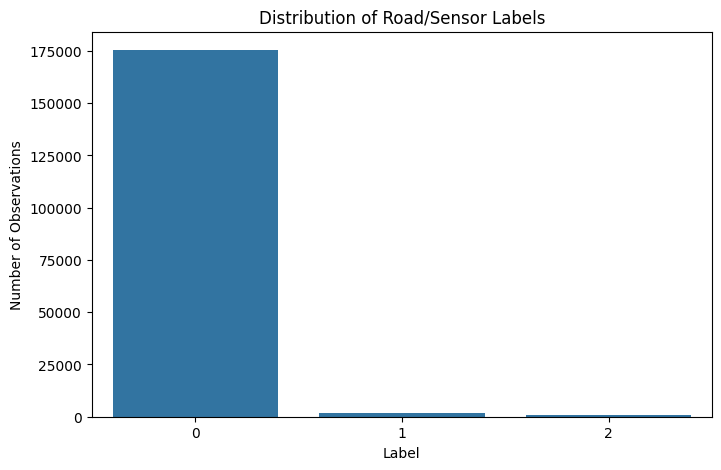

In [66]:
label_counts = df['label'].value_counts().sort_index()

print(label_counts)

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='label')

plt.title('Distribution of Road/Sensor Labels')
plt.xlabel('Label')
plt.ylabel('Number of Observations')

plt.show()

<Axes: xlabel='acc_z', ylabel='Density'>

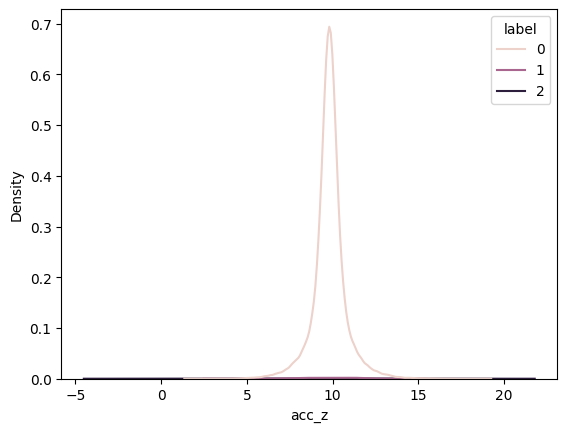

In [67]:
sns.kdeplot(data=df, x='acc_z', hue='label')

In [68]:
label_percentage = df['label'].value_counts(normalize=True).sort_index() * 100

print(label_percentage.round(2))

label
0    98.67
1     0.88
2     0.45
Name: proportion, dtype: float64


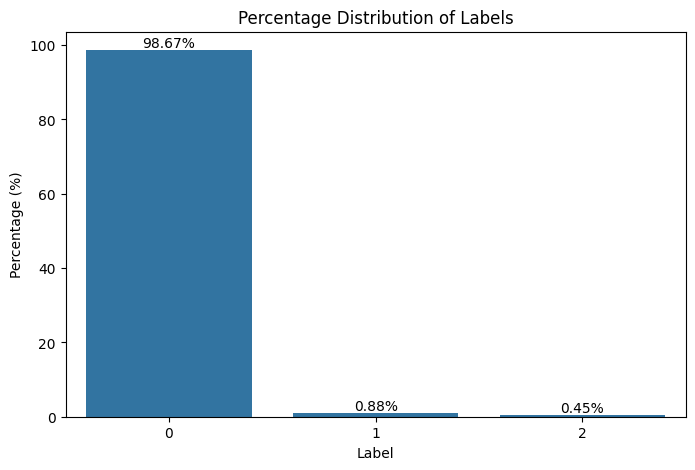

In [69]:
plt.figure(figsize=(8,5))

ax = sns.barplot(
    x=label_percentage.index,
    y=label_percentage.values
)

for i, value in enumerate(label_percentage.values):
    ax.text(i, value, f'{value:.2f}%',
            ha='center', va='bottom')

plt.title('Percentage Distribution of Labels')
plt.xlabel('Label')
plt.ylabel('Percentage (%)')

plt.show()

**Insight:** the data is severely imbalanced: 98.67% smooth, 0.88% speed breaker and 0.45% pothole rows. Plain accuracy will be misleading, so the models use class weights and are judged by macro-F1 and per-class recall.

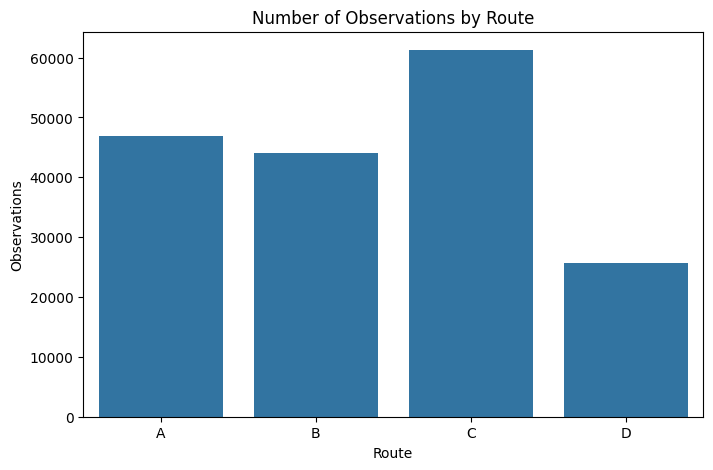

In [70]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='route_id')

plt.title('Number of Observations by Route')
plt.xlabel('Route')
plt.ylabel('Observations')

plt.show()

In [71]:
route_label = pd.crosstab(
    df['route_id'],
    df['label'],
    normalize='index'
) * 100

route_label

label,0,1,2
route_id,,,
A,98.731722,0.799335,0.468943
B,98.595327,0.981907,0.422766
C,98.669800,0.873199,0.457001
D,98.699422,0.839713,0.460865


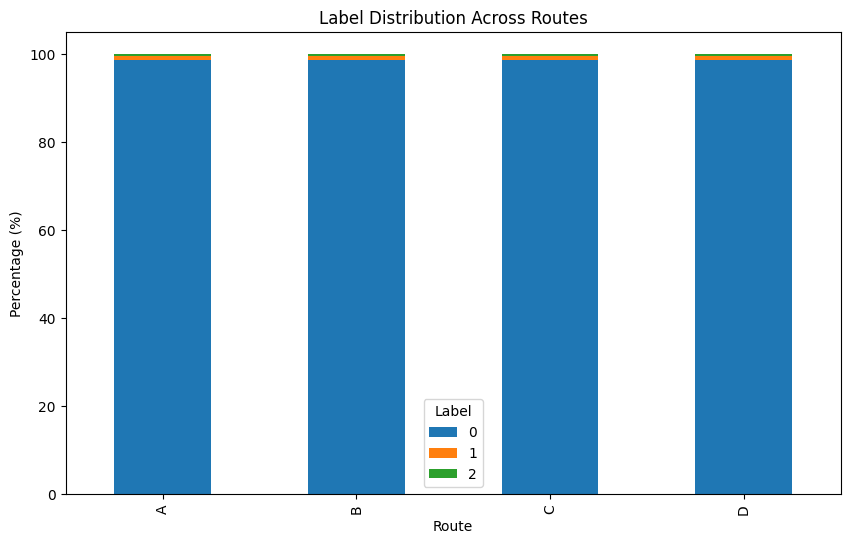

In [72]:
route_label.plot(
    kind='bar',
    stacked=True,
    figsize=(10,6)
)

plt.title('Label Distribution Across Routes')
plt.xlabel('Route')
plt.ylabel('Percentage (%)')
plt.legend(title='Label')

plt.show()

**Insight:** every route has a similar event mix (speed breakers 0.80% to 0.98% of rows, potholes 0.42% to 0.47%), so holding out one route for testing is fair in terms of class balance.

## 3. Sensor signal distributions

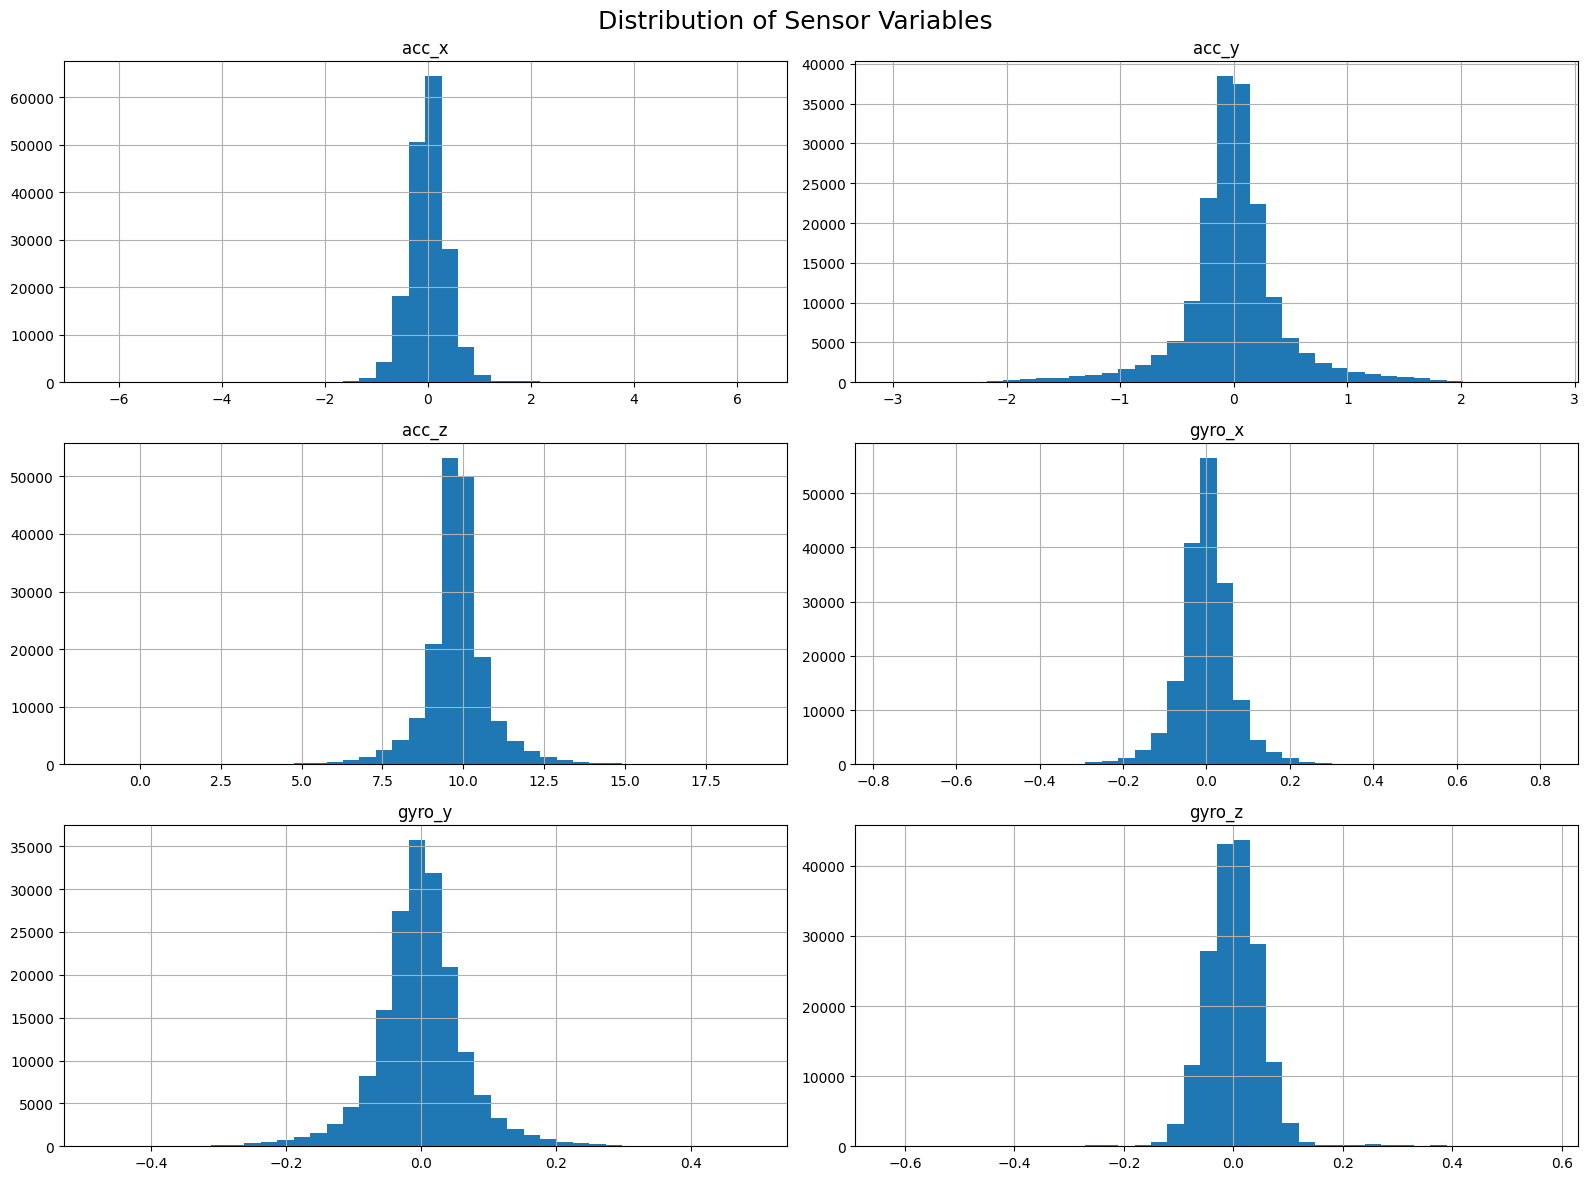

In [73]:
sensor_cols = ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']

df[sensor_cols].hist(
    figsize=(16,12),
    bins=40
)

plt.suptitle(
    'Distribution of Sensor Variables',
    fontsize=18
)

plt.tight_layout()
plt.show()

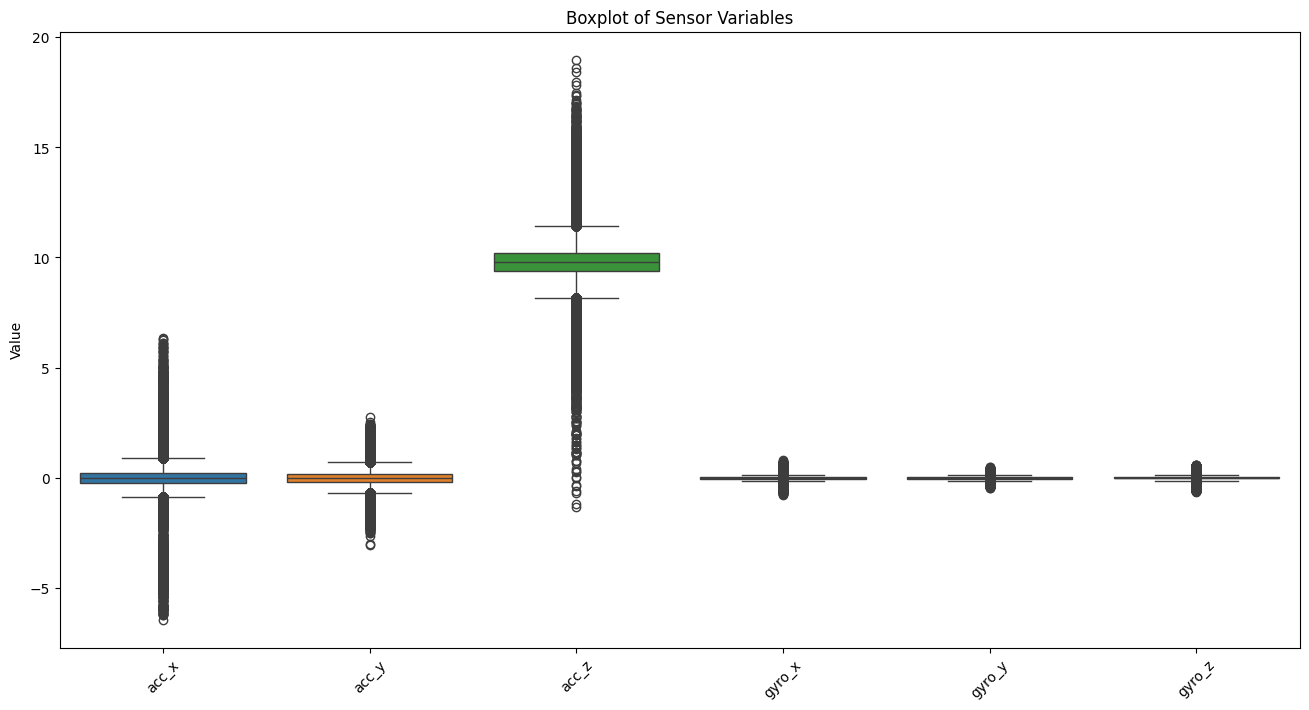

In [74]:
plt.figure(figsize=(16,8))

sns.boxplot(data=df[sensor_cols])

plt.title('Boxplot of Sensor Variables')
plt.xticks(rotation=45)
plt.ylabel('Value')

plt.show()

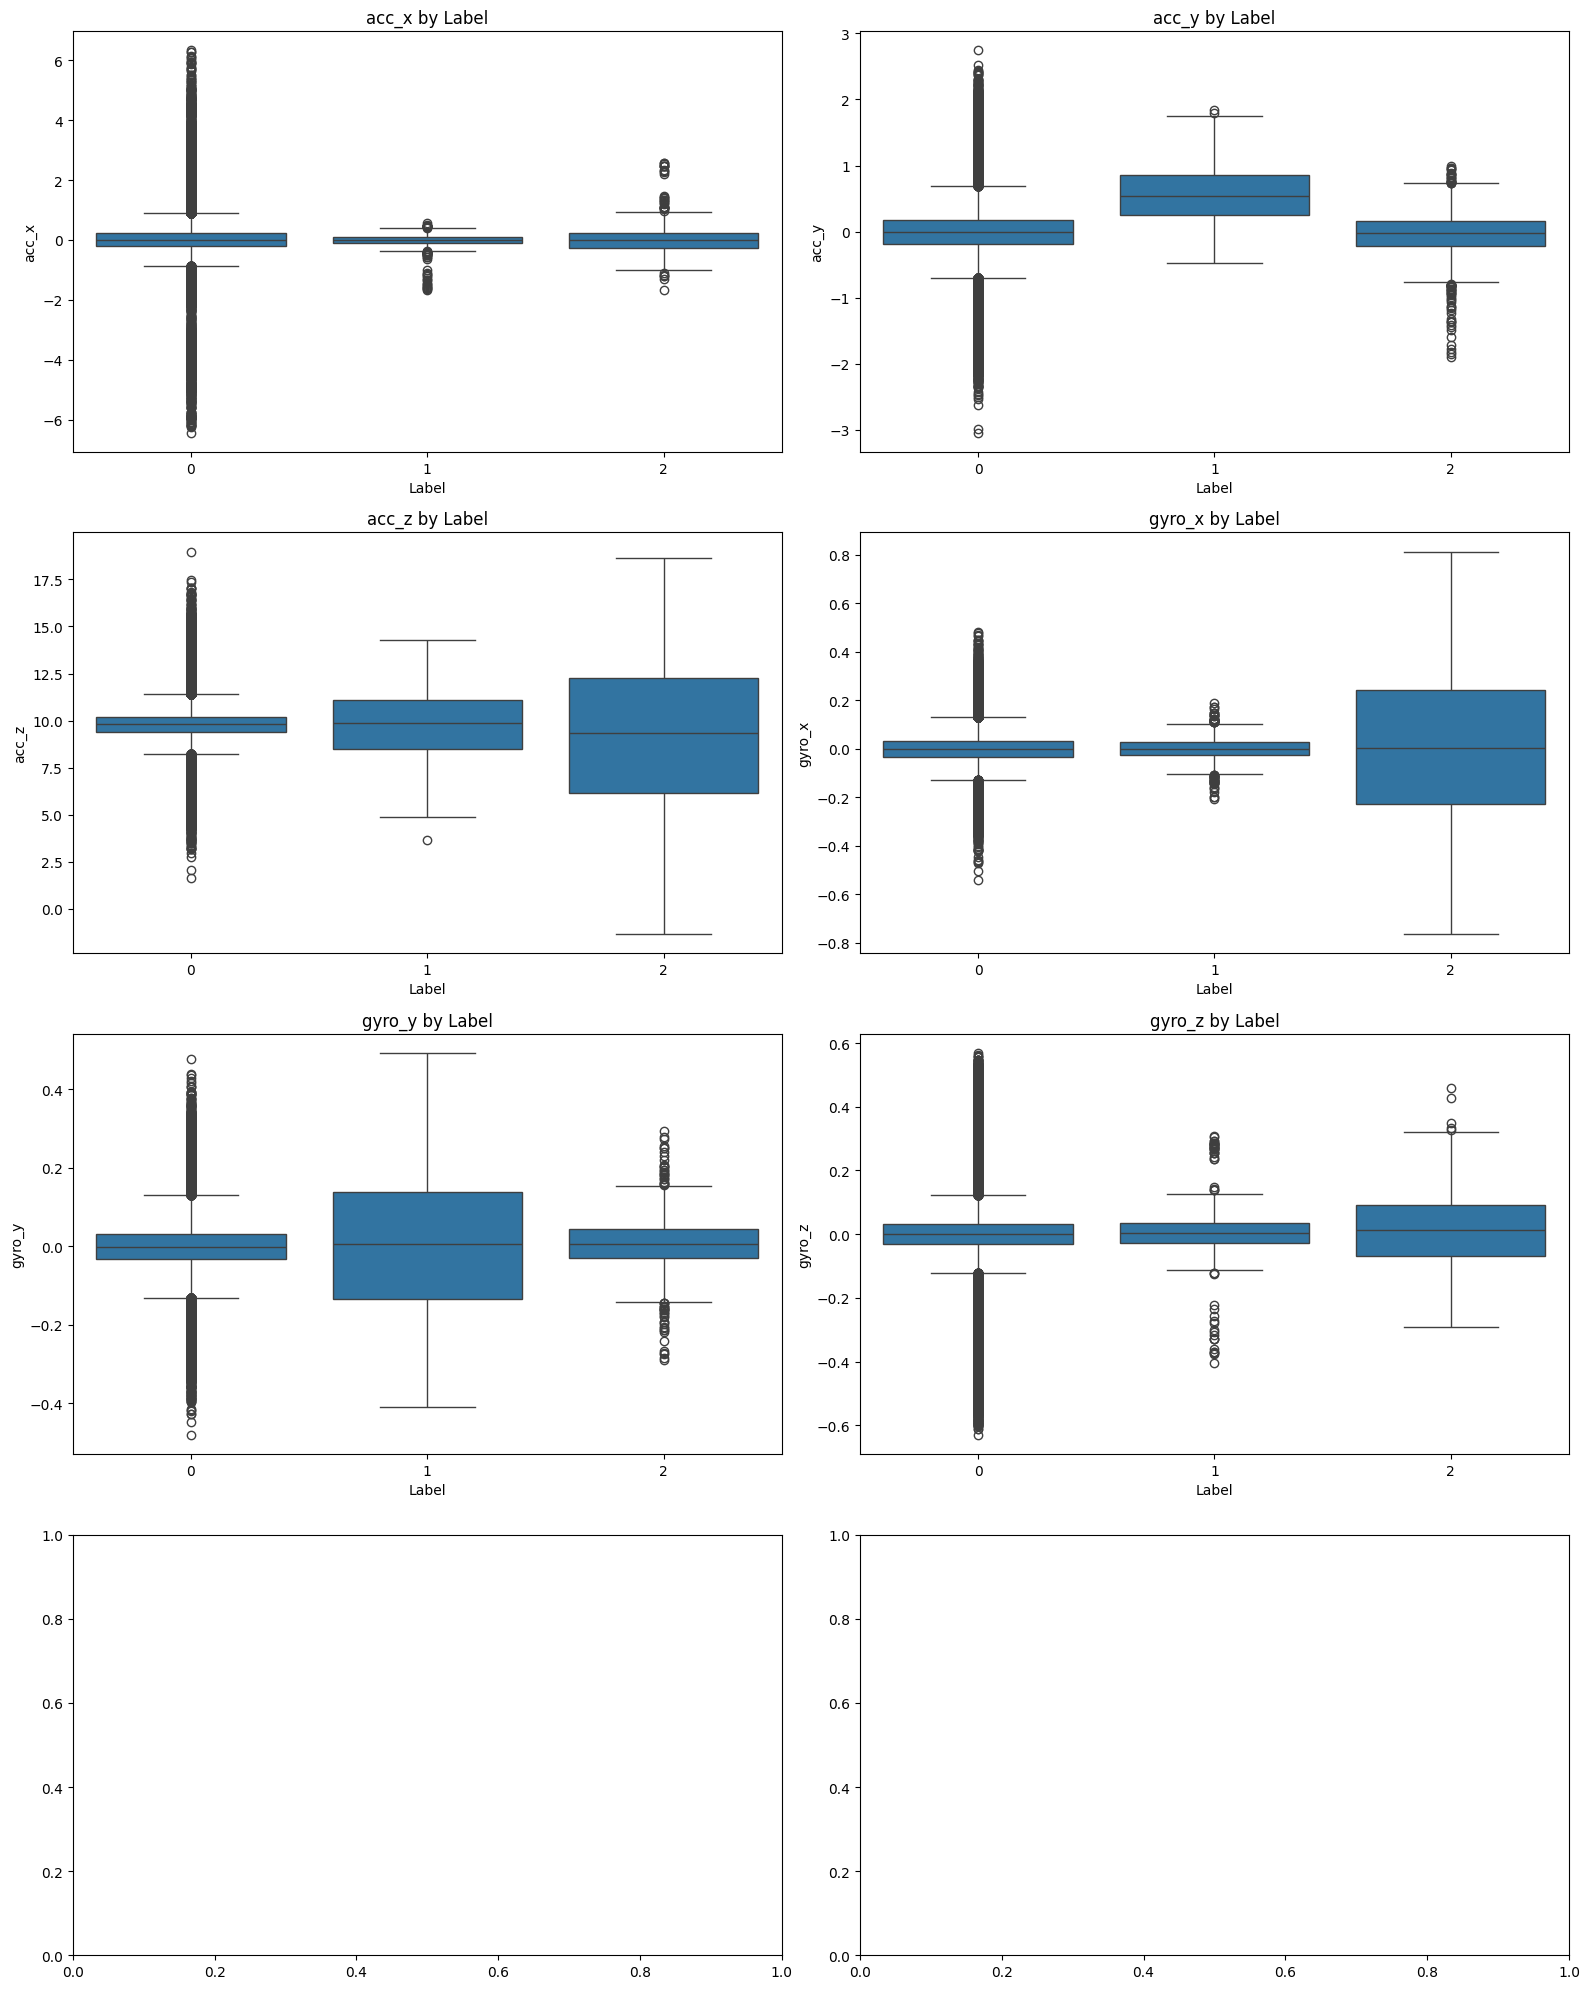

In [75]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(16,20)
)

axes = axes.flatten()

for i, col in enumerate(sensor_cols):

    sns.boxplot(
        data=df,
        x='label',
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} by Label')
    axes[i].set_xlabel('Label')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

**Insight:** potholes stand out in vibration and rotation: gravity-removed `acc_z` has a std of 4.02 for potholes vs 0.98 for smooth road, and `gyro_x` has a std of 0.311 vs 0.065. Speed breakers show a positive mean `acc_y` (0.56 vs about 0), which is braking before the bump.

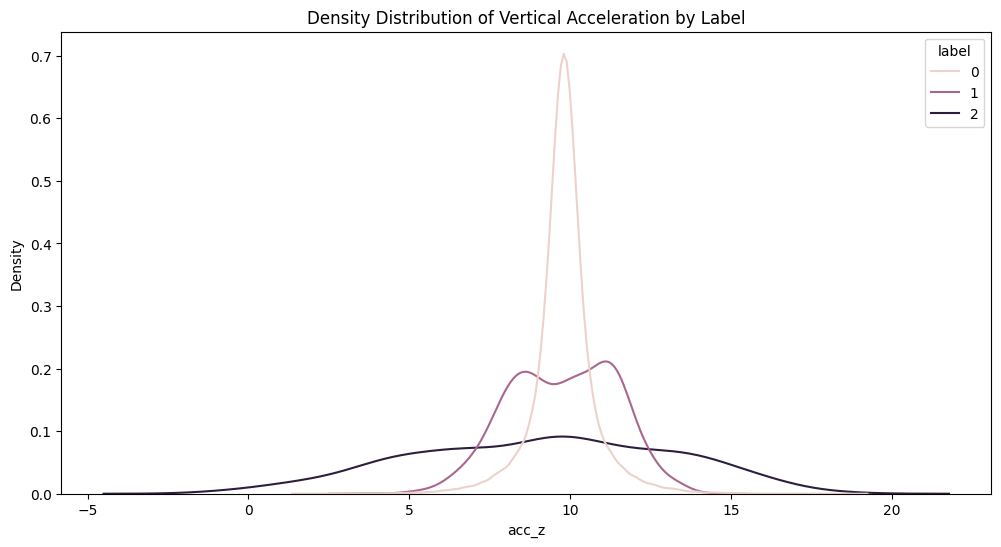

In [76]:
plt.figure(figsize=(12,6))

sns.kdeplot(
    data=df,
    x='acc_z',
    hue='label',
    common_norm=False
)

plt.title('Density Distribution of Vertical Acceleration by Label')
plt.xlabel('acc_z')
plt.ylabel('Density')

plt.show()

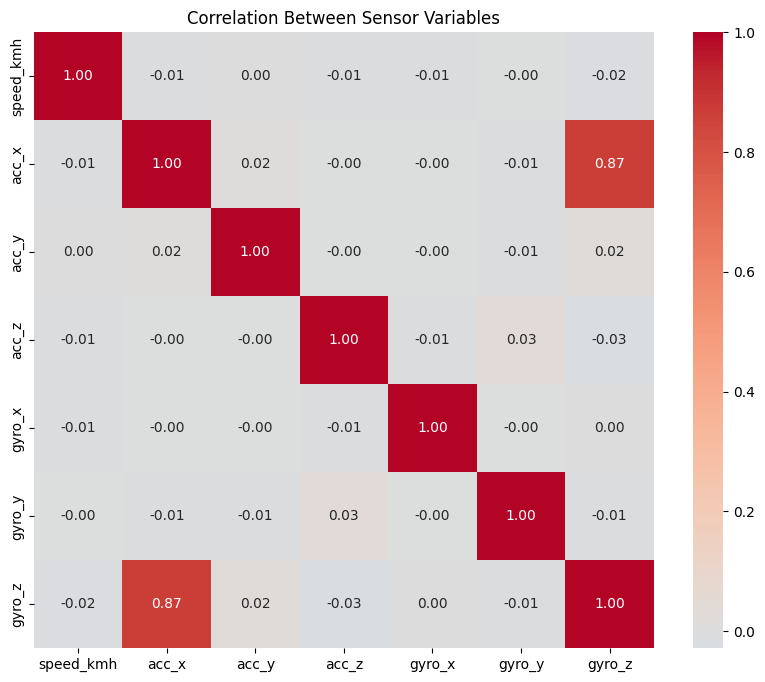

In [77]:
corr_cols = [
    'speed_kmh',
    'acc_x',
    'acc_y',
    'acc_z',
    'gyro_x',
    'gyro_y',
    'gyro_z'
]

corr = df[corr_cols].corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Between Sensor Variables')

plt.show()

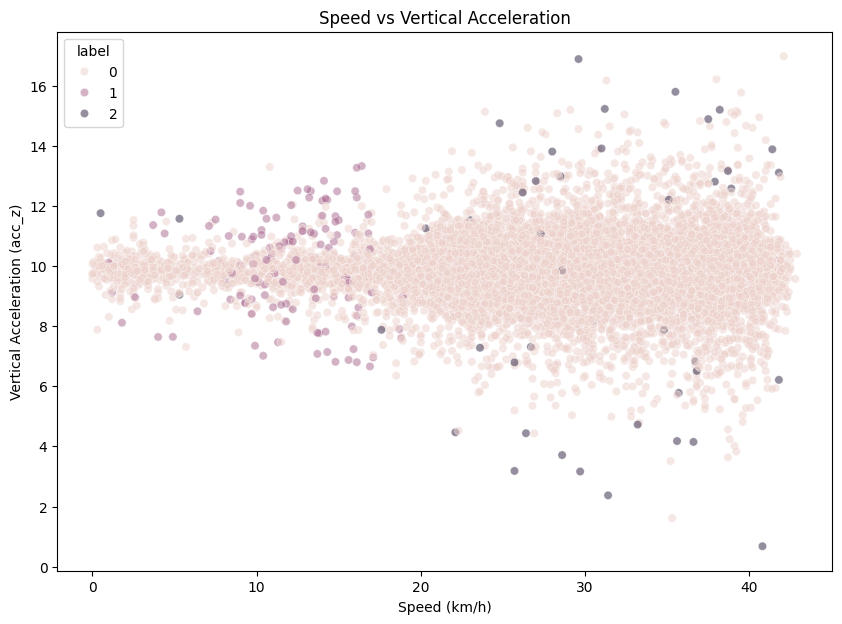

In [78]:
sample_df = df.sample(
    min(15000, len(df)),
    random_state=42
)

plt.figure(figsize=(10,7))

sns.scatterplot(
    data=sample_df,
    x='speed_kmh',
    y='acc_z',
    hue='label',
    alpha=0.5
)

plt.title('Speed vs Vertical Acceleration')
plt.xlabel('Speed (km/h)')
plt.ylabel('Vertical Acceleration (acc_z)')

plt.show()

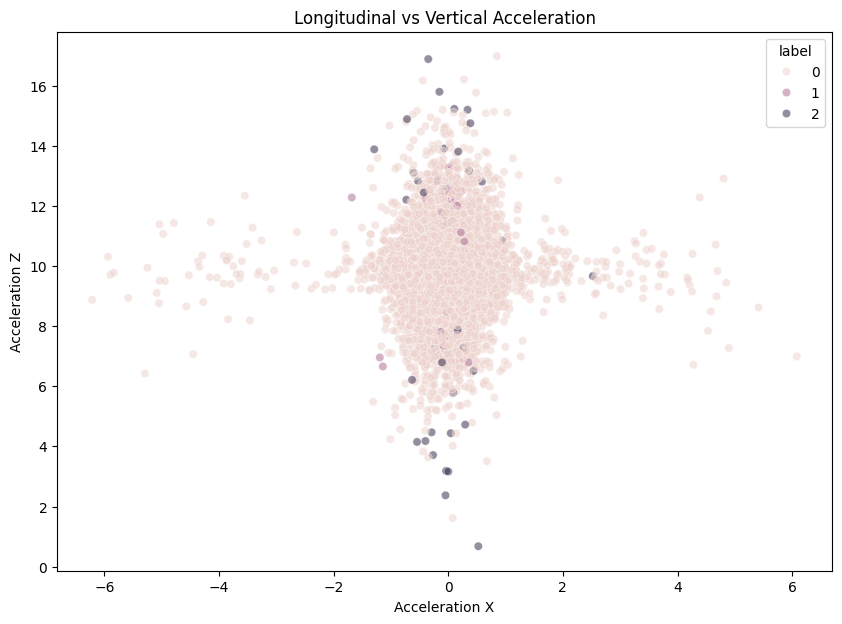

In [79]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=sample_df,
    x='acc_x',
    y='acc_z',
    hue='label',
    alpha=0.5
)

plt.title('Longitudinal vs Vertical Acceleration')
plt.xlabel('Acceleration X')
plt.ylabel('Acceleration Z')

plt.show()

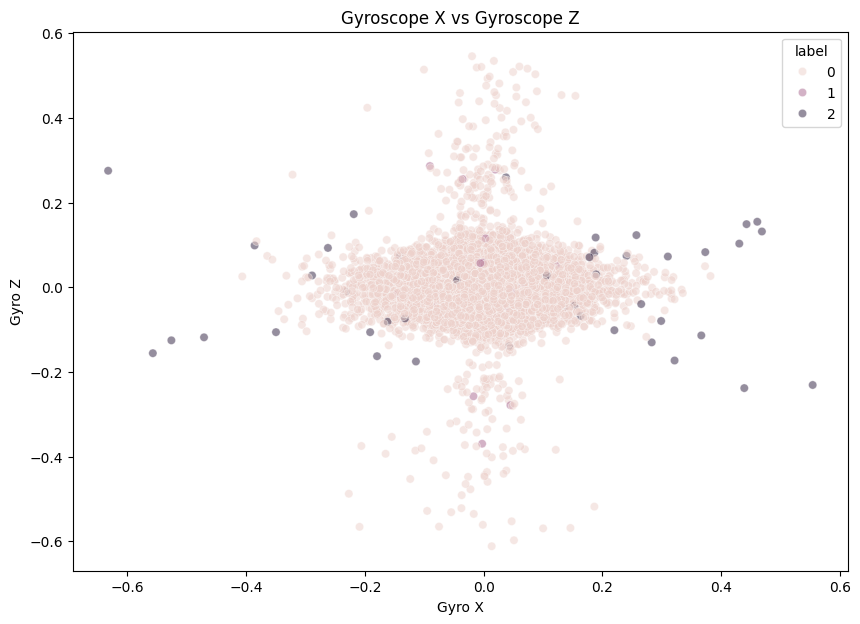

In [80]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=sample_df,
    x='gyro_x',
    y='gyro_z',
    hue='label',
    alpha=0.5
)

plt.title('Gyroscope X vs Gyroscope Z')
plt.xlabel('Gyro X')
plt.ylabel('Gyro Z')

plt.show()


## 4. Feature engineering: remove gravity

In [81]:
GRAVITY = 9.81
df = df.sort_values(['ride_id', 'time_s']).reset_index(drop=True)
df['acc_z_dyn'] = df['acc_z'] - GRAVITY          # vibration only, gravity removed
df['acc_magnitude'] = np.sqrt(df['acc_x']**2 + df['acc_y']**2 + df['acc_z_dyn']**2)
df[['acc_z', 'acc_z_dyn', 'acc_magnitude']].describe().T

,count,mean,std,min,25%,50%,75%,max
acc_z,177783.0,9.810009,1.023900,-1.341000,9.404000,9.812000,10.219000,18.982000
acc_z_dyn,177783.0,0.000009,1.023900,-11.151000,-0.406000,0.002000,0.409000,9.172000
acc_magnitude,177783.0,0.931965,0.799608,0.005385,0.428929,0.690413,1.155256,11.151996


In [82]:
df['gyro_magnitude'] = np.sqrt(
    df['gyro_x']**2 +
    df['gyro_y']**2 +
    df['gyro_z']**2
)

df[['gyro_x', 'gyro_y', 'gyro_z', 'gyro_magnitude']].head()

,gyro_x,gyro_y,gyro_z,gyro_magnitude
0,-0.1186,-0.0072,-0.0044,0.118900
1,-0.0494,-0.0382,0.0414,0.074924
2,-0.0595,-0.0394,-0.0543,0.089672
3,-0.1217,-0.0304,-0.0038,0.125497
4,-0.0057,-0.0469,-0.0201,0.051343


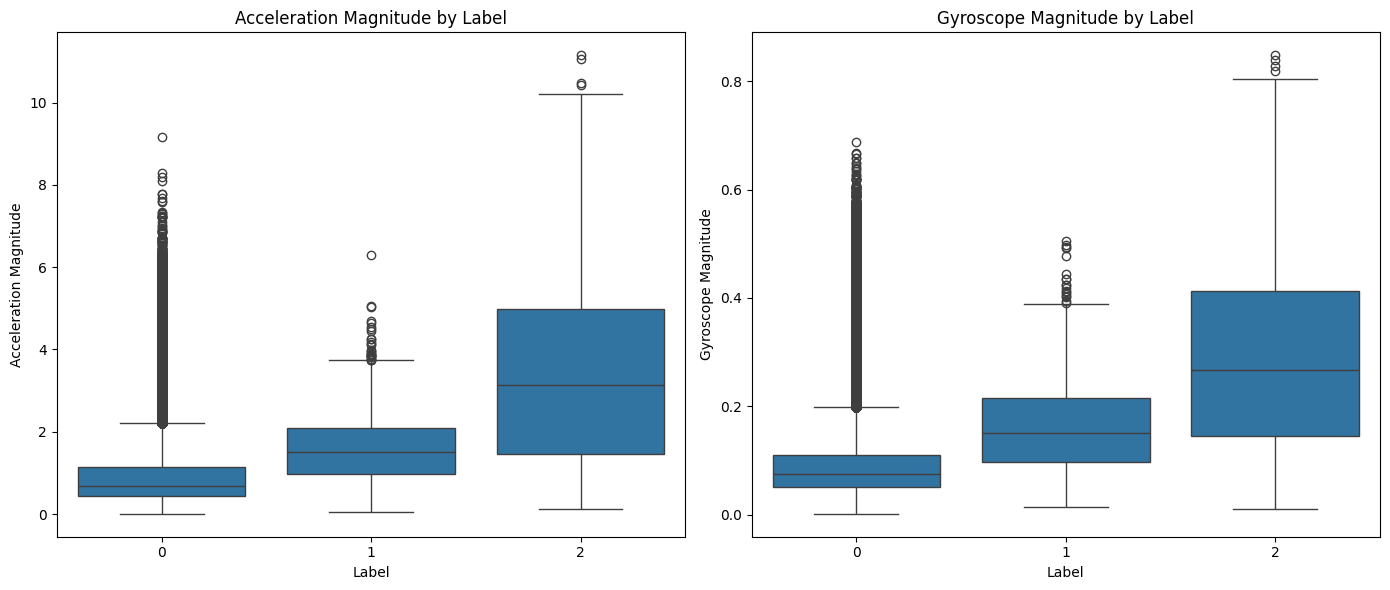

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.boxplot(
    data=df,
    x='label',
    y='acc_magnitude',
    ax=axes[0]
)

axes[0].set_title('Acceleration Magnitude by Label')
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Acceleration Magnitude')


sns.boxplot(
    data=df,
    x='label',
    y='gyro_magnitude',
    ax=axes[1]
)

axes[1].set_title('Gyroscope Magnitude by Label')
axes[1].set_xlabel('Label')
axes[1].set_ylabel('Gyroscope Magnitude')

plt.tight_layout()
plt.show()

## 5. Time-series view of one ride

In [84]:
ride = df[df['ride_id'] == df['ride_id'].iloc[0]].sort_values('time_s')

ride.head()

,ride_id,route_id,time_s,lat,lon,speed_kmh,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,label,acc_z_dyn,acc_magnitude,gyro_magnitude
0,R01,A,0.00,18.508667,73.803025,38.4,0.126,0.062,10.450,-0.1186,-0.0072,-0.0044,0,0.640,0.655225,0.118900
1,R01,A,0.05,18.508667,73.803025,40.1,-0.117,0.241,9.495,-0.0494,-0.0382,0.0414,0,-0.315,0.413515,0.074924
2,R01,A,0.10,18.508667,73.803025,38.6,-0.052,0.088,10.297,-0.0595,-0.0394,-0.0543,0,0.487,0.497611,0.089672
3,R01,A,0.15,18.508667,73.803025,39.7,-0.288,-0.155,10.133,-0.1217,-0.0304,-0.0038,0,0.323,0.459672,0.125497
4,R01,A,0.20,18.508667,73.803025,39.0,-0.283,-0.310,8.636,-0.0057,-0.0469,-0.0201,0,-1.174,1.246782,0.051343


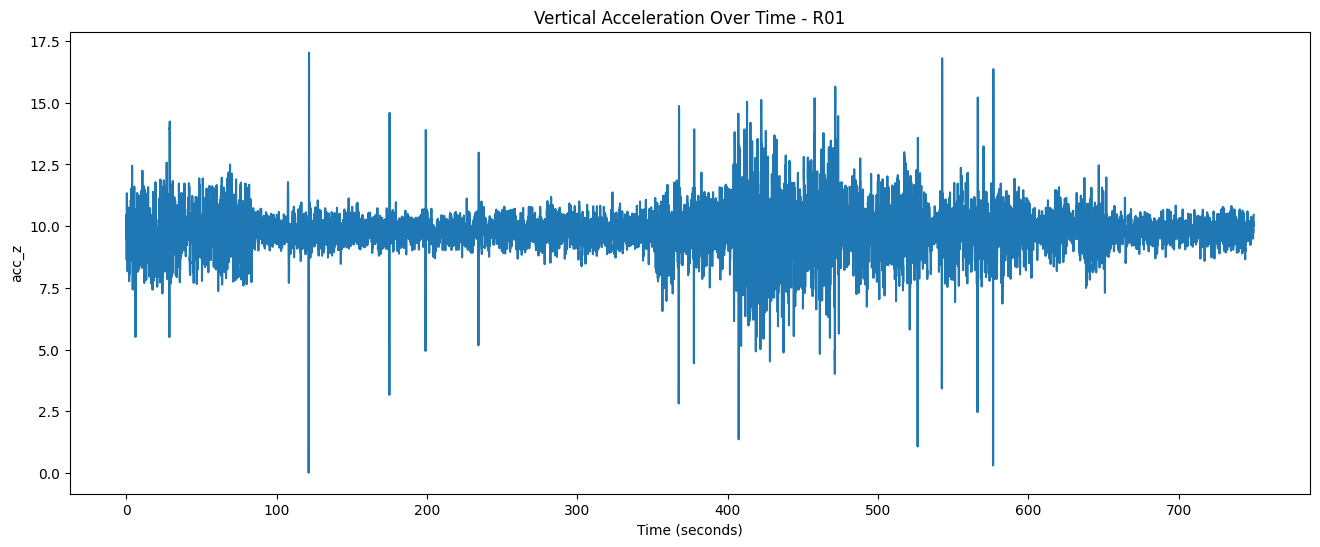

In [85]:
plt.figure(figsize=(16,6))

plt.plot(
    ride['time_s'],
    ride['acc_z']
)

plt.title(f'Vertical Acceleration Over Time - {ride["ride_id"].iloc[0]}')
plt.xlabel('Time (seconds)')
plt.ylabel('acc_z')

plt.show()

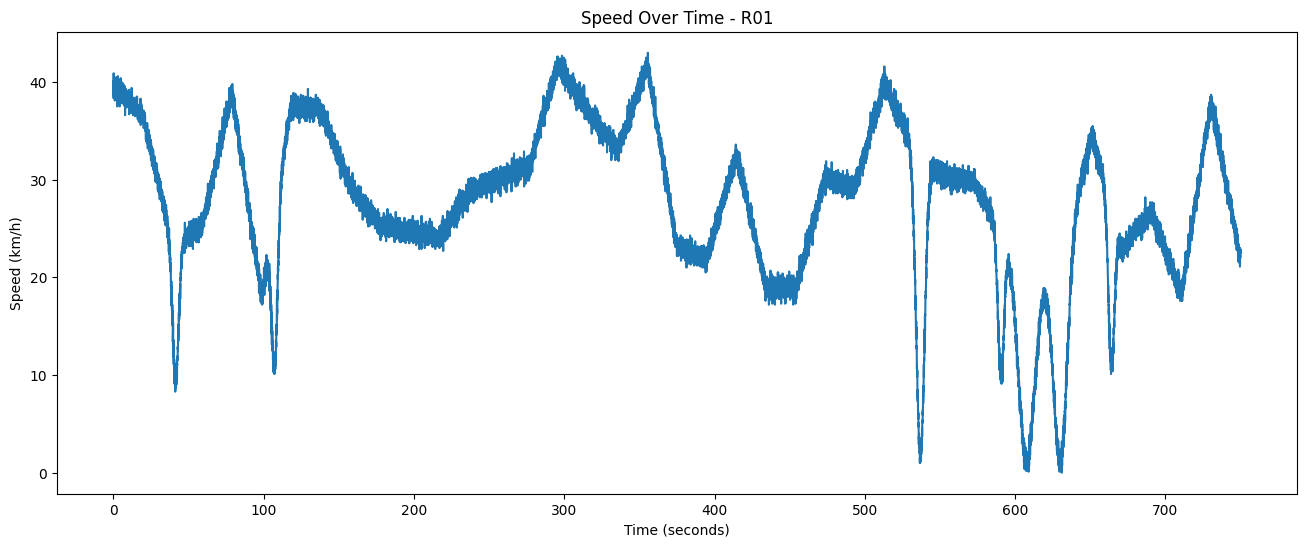

In [86]:
plt.figure(figsize=(16,6))

plt.plot(
    ride['time_s'],
    ride['speed_kmh']
)

plt.title(f'Speed Over Time - {ride["ride_id"].iloc[0]}')
plt.xlabel('Time (seconds)')
plt.ylabel('Speed (km/h)')

plt.show()

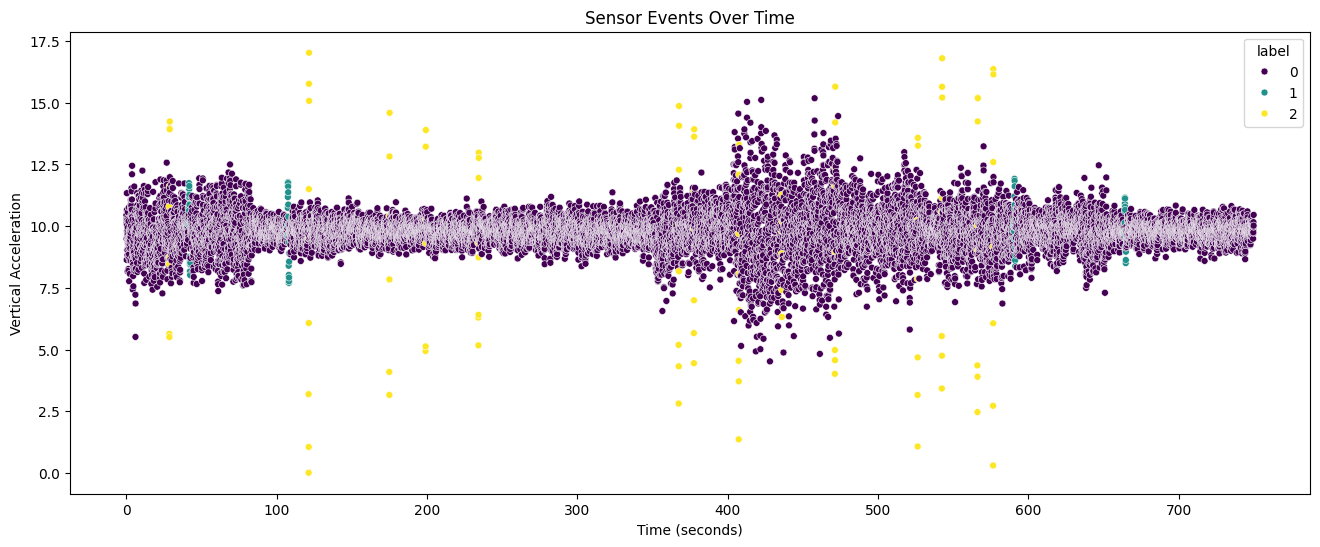

In [87]:
plt.figure(figsize=(16,6))

sns.scatterplot(
    data=ride,
    x='time_s',
    y='acc_z',
    hue='label',
    palette='viridis',
    s=25
)

plt.title('Sensor Events Over Time')
plt.xlabel('Time (seconds)')
plt.ylabel('Vertical Acceleration')

plt.show()

In [88]:
df['acc_z_rolling_mean'] = df.groupby('ride_id')['acc_z'].transform(
    lambda s: s.rolling(20, center=True, min_periods=1).mean())
df['acc_z_rolling_std'] = df.groupby('ride_id')['acc_z'].transform(
    lambda s: s.rolling(20, center=True, min_periods=1).std())
ride = df[df['ride_id'] == 'R01'].copy()

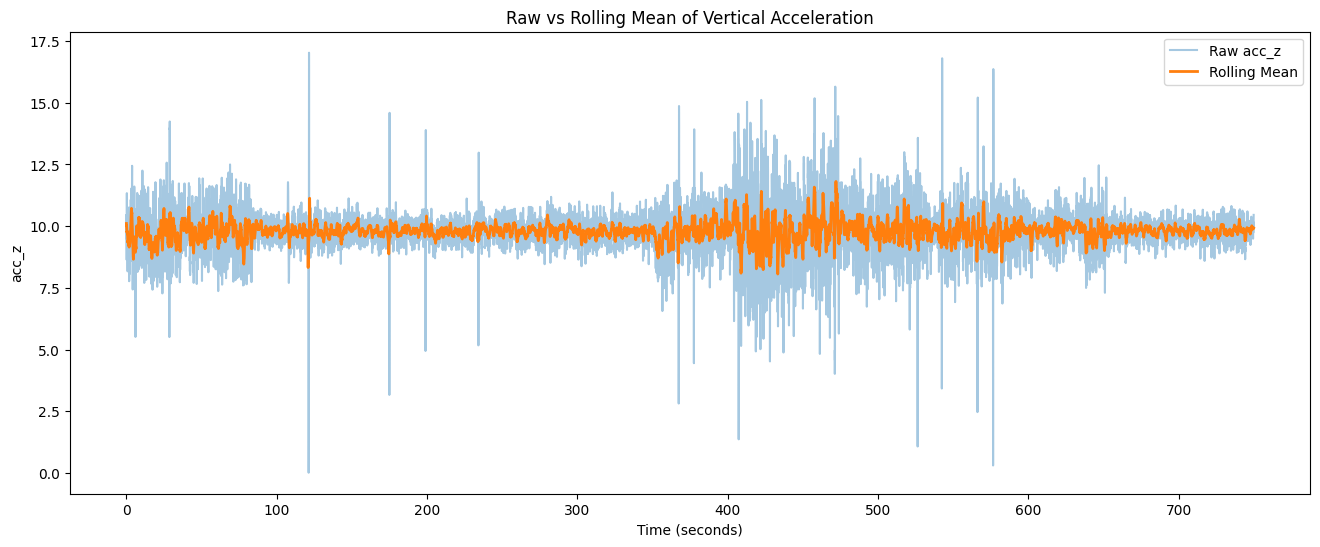

In [89]:
plt.figure(figsize=(16,6))

plt.plot(
    ride['time_s'],
    ride['acc_z'],
    alpha=0.4,
    label='Raw acc_z'
)

plt.plot(
    ride['time_s'],
    ride['acc_z_rolling_mean'],
    linewidth=2,
    label='Rolling Mean'
)

plt.title('Raw vs Rolling Mean of Vertical Acceleration')
plt.xlabel('Time (seconds)')
plt.ylabel('acc_z')

plt.legend()
plt.show()

In [90]:
ride['acc_z_rolling_std'] = (
    ride['acc_z']
    .rolling(window=20)
    .std()
)

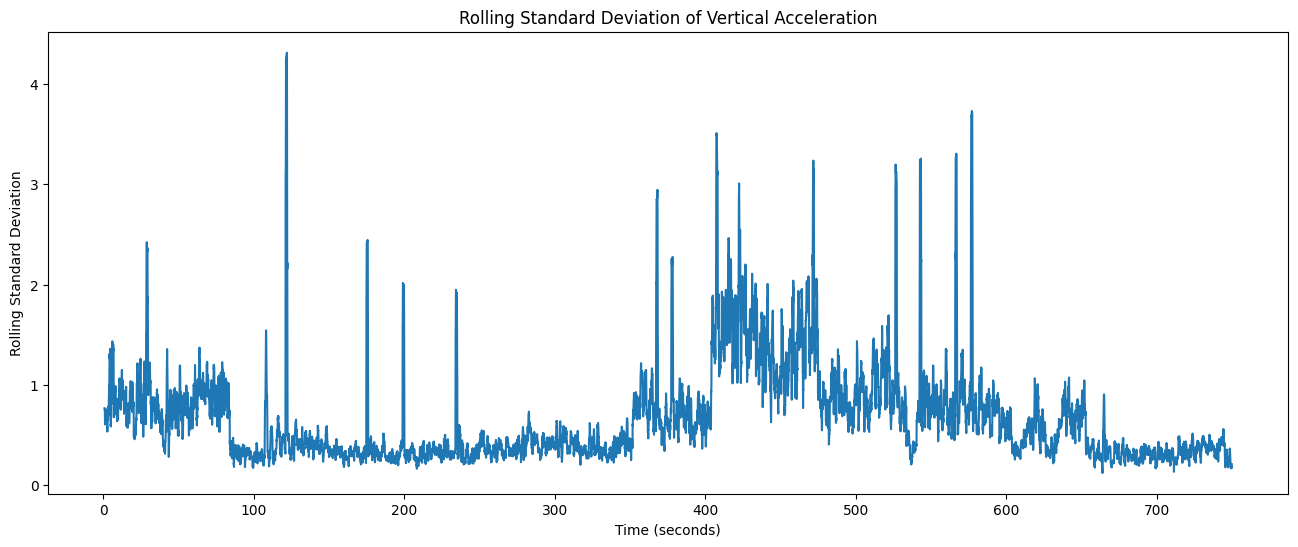

In [91]:
plt.figure(figsize=(16,6))

plt.plot(
    ride['time_s'],
    ride['acc_z_rolling_std']
)

plt.title('Rolling Standard Deviation of Vertical Acceleration')
plt.xlabel('Time (seconds)')
plt.ylabel('Rolling Standard Deviation')

plt.show()

## 6. GPS and route geography


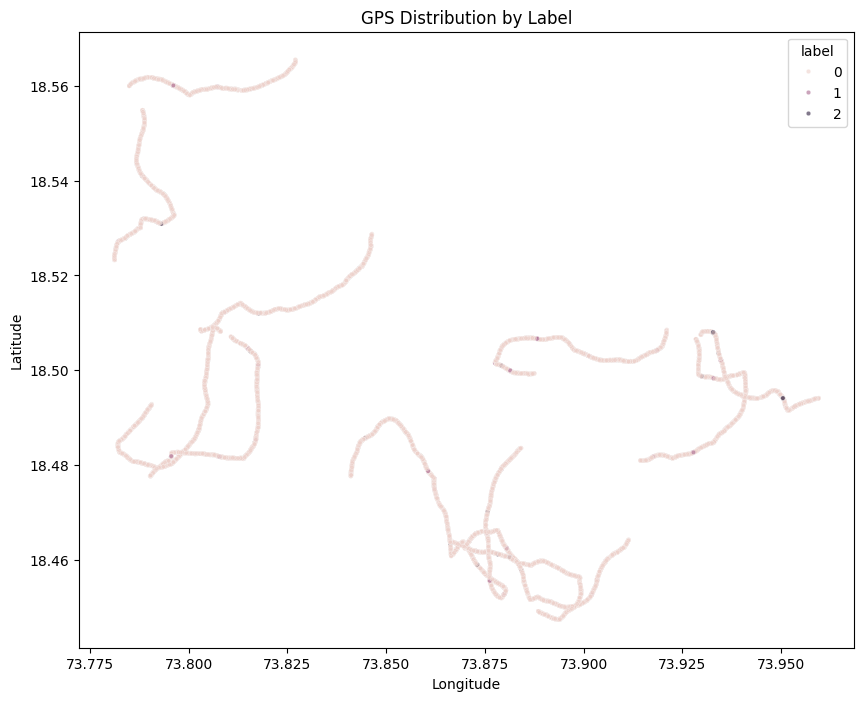

In [92]:
plt.figure(figsize=(10,8))

sns.scatterplot(
    data=df.sample(min(20000, len(df)), random_state=42),
    x='lon',
    y='lat',
    hue='label',
    s=10,
    alpha=0.6
)

plt.title('GPS Distribution by Label')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

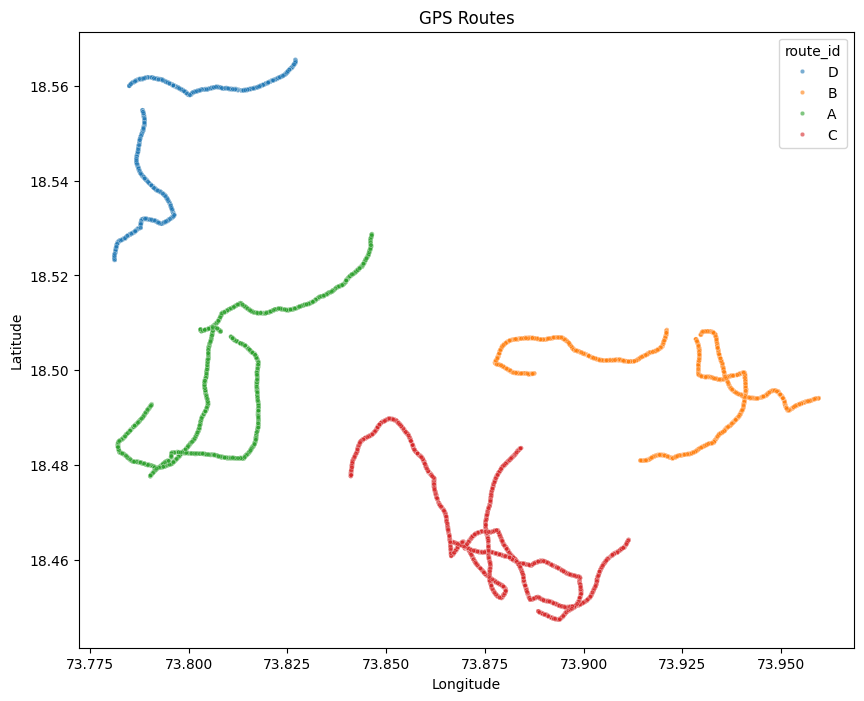

In [93]:
plt.figure(figsize=(10,8))

sns.scatterplot(
    data=df.sample(min(20000, len(df)), random_state=42),
    x='lon',
    y='lat',
    hue='route_id',
    s=10,
    alpha=0.6
)

plt.title('GPS Routes')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

In [94]:
label_stats = df.groupby('label')[sensor_cols].agg(
    ['mean', 'std', 'min', 'max']
)

label_stats

acc_x                             acc_y                          \
           mean       std    min    max      mean       std    min    max   
label                                                                       
0      0.005593  0.508922 -6.436  6.325 -0.005777  0.447117 -3.043  2.741   
1     -0.004740  0.215245 -1.682  0.557  0.563434  0.425951 -0.479  1.843   
2      0.024578  0.497411 -1.662  2.563 -0.052815  0.414425 -1.894  0.993   

          acc_z            ...  gyro_x            gyro_y                    \
           mean       std  ...     min     max      mean       std     min   
label                      ...                                               
0      9.813615  0.980637  ... -0.5399  0.4806 -0.000312  0.065185 -0.4805   
1      9.769641  1.661247  ... -0.2060  0.1885  0.002649  0.164849 -0.4103   
2      9.101408  4.021329  ... -0.7637  0.8126  0.006364  0.076904 -0.2899   

                 gyro_z                            
          max      mean       std     min     max  
label                                              
0      0.4770  0.000863  0.061896 -0.6307  0.5698  
1      0.4933  0.005332  0.064754 -0.4060  0.3088  
2      0.2929  0.011953  0.116349 -0.2901  0.4582  

[3 rows x 24 columns]

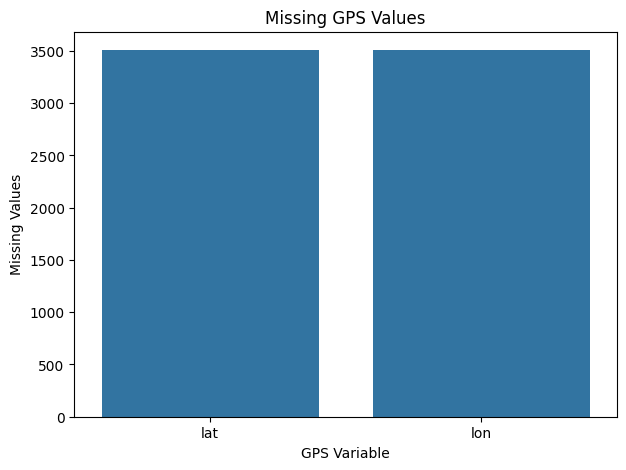

In [95]:
gps_missing = df[['lat', 'lon']].isnull().sum()

plt.figure(figsize=(7,5))

sns.barplot(
    x=gps_missing.index,
    y=gps_missing.values
)

plt.title('Missing GPS Values')
plt.xlabel('GPS Variable')
plt.ylabel('Missing Values')

plt.show()

**Insight:** about 1.97% of GPS readings are missing, in short gaps. They are interpolated per ride in the next cell, never across rides.

In [96]:
df[['lat', 'lon']] = df.groupby('ride_id')[['lat', 'lon']].transform(
    lambda s: s.interpolate(limit_direction='both'))
print("Missing GPS after fix:\n", df[['lat', 'lon']].isnull().sum())

dt = df.groupby('ride_id')['time_s'].diff().dropna()
print("\nSampling rate: ~", round(1 / dt.median()), "Hz")
print("Time strictly increasing:", (dt > 0).all())

Missing GPS after fix:
 lat    0
lon    0
dtype: int64

Sampling rate: ~ 20 Hz
Time strictly increasing: True


## 7. Event analysis

In [97]:
event_names = {1: 'Speed breaker', 2: 'Pothole'}
prev = df.groupby('ride_id')['label'].shift(1).fillna(0)
df['event_start'] = (df['label'] > 0) & (df['label'] != prev)

events = df[df['event_start']]
ride_summary = (events.groupby(['ride_id', 'label']).size()
                .unstack(fill_value=0).rename(columns=event_names))
ride_summary['duration_min'] = df.groupby('ride_id')['time_s'].max() / 60
ride_summary['mean_speed_kmh'] = df.groupby('ride_id')['speed_kmh'].mean()
ride_summary['route'] = df.groupby('ride_id')['route_id'].first()
display(ride_summary.round(2))
print(ride_summary[['Speed breaker', 'Pothole']].sum())

label,Speed breaker,Pothole,duration_min,mean_speed_kmh,route
ride_id,,,,,
R01,4,14,12.50,27.84,A
R02,8,8,12.78,28.99,A
R03,6,7,13.82,29.73,A
R04,7,4,12.64,29.43,B
R05,8,5,13.80,28.38,B
R06,5,16,10.22,26.91,B
R07,10,10,13.58,28.32,C
R08,9,11,13.93,27.05,C
R09,5,8,11.92,28.49,C


label
Speed breaker     74
Pothole          106
dtype: int64


In [98]:
seg_id = (df['label'] != df.groupby('ride_id')['label'].shift(1)).cumsum()
seg = df.groupby(seg_id.rename('seg')).agg(label=('label', 'first'), n=('label', 'size'))
seg['duration_s'] = seg['n'] / 20
seg[seg['label'] > 0].groupby('label')['duration_s'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
1,74.0,1.05,0.17,0.8,0.90,1.05,1.15,1.35
2,106.0,0.38,0.06,0.3,0.35,0.40,0.45,0.45


**Insight:** the dataset has 74 speed breakers and 106 potholes. Speed breakers last about 1.05 s and potholes about 0.38 s, so a 2-second window covers either one.

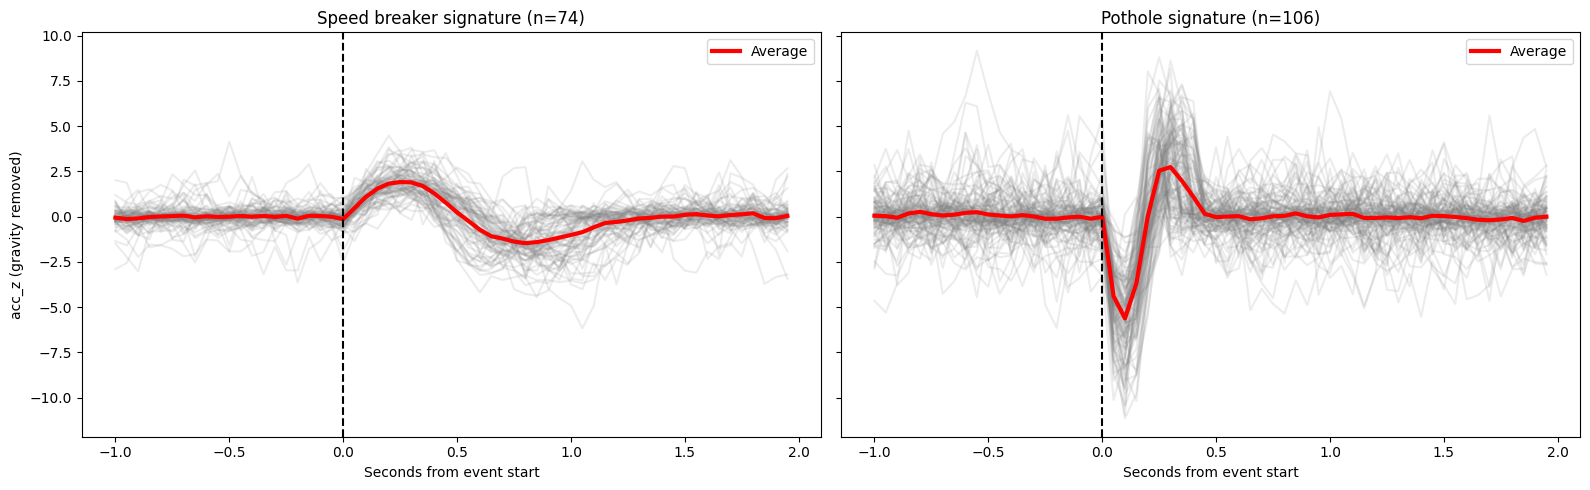

In [99]:
PRE, POST = 20, 40
t_axis = np.arange(-PRE, POST) / 20
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, lab in zip(axes, [1, 2]):
    waves = []
    for rid, g in df.groupby('ride_id'):
        z = g['acc_z_dyn'].to_numpy()
        starts = np.where(g['event_start'].to_numpy() & (g['label'].to_numpy() == lab))[0]
        for s in starts:
            if s - PRE >= 0 and s + POST <= len(z):
                waves.append(z[s - PRE:s + POST])
    waves = np.array(waves)
    ax.plot(t_axis, waves.T, color='gray', alpha=0.15)
    ax.plot(t_axis, waves.mean(axis=0), color='red', linewidth=3, label='Average')
    ax.axvline(0, color='black', linestyle='--')
    ax.set_title(f'{event_names[lab]} signature (n={len(waves)})')
    ax.set_xlabel('Seconds from event start')
    ax.legend()
axes[0].set_ylabel('acc_z (gravity removed)')
plt.tight_layout()
plt.show()

**Insight:** the two events have very different shapes. A speed breaker is a slow rise and fall, and a pothole is a sharp dip followed by a rebound. A model needs a window of readings, not a single reading.

In [100]:
df['big_jolt'] = df['acc_z_dyn'].abs() > 3
print("% of each class that gives a big jolt:")
print((pd.crosstab(df['label'], df['big_jolt'], normalize='index') * 100).round(2))
print("\nOf all big jolts, % that belong to each class:")
print((df.loc[df['big_jolt'], 'label'].value_counts(normalize=True).sort_index() * 100).round(1))

% of each class that gives a big jolt:
big_jolt  False  True 
label                 
0         98.06   1.94
1         94.73   5.27
2         48.51  51.49

Of all big jolts, % that belong to each class:
label
0    87.3
1     2.1
2    10.6
Name: proportion, dtype: float64


**Insight:** a simple threshold fails. Only 51.5% of pothole rows exceed |acc_z| of 3, and 87.3% of all big jolts come from ordinary rough road. Real detection needs several signals together.

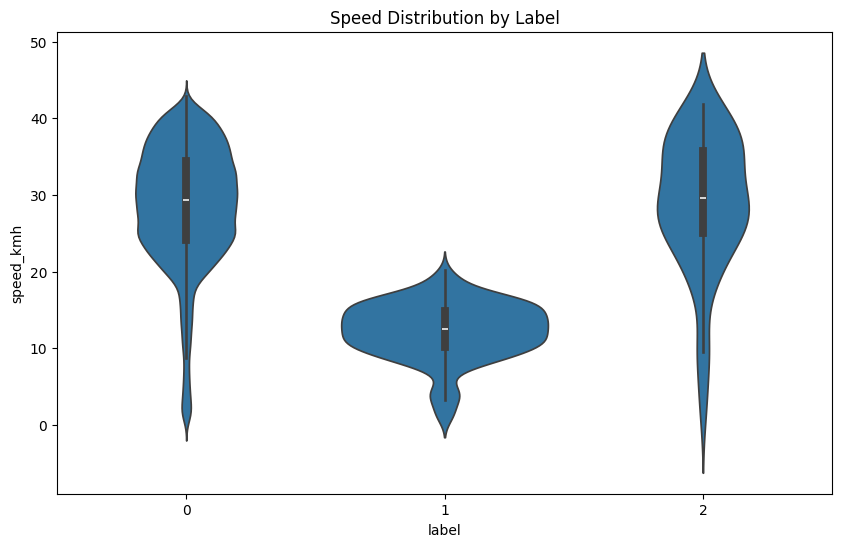

Speed breaker vs smooth road speed: p = 0.0000
Pothole vs smooth road speed: p = 0.1710


In [101]:
from scipy import stats

plt.figure(figsize=(10, 6))
sns.violinplot(data=df.sample(30000, random_state=42), x='label', y='speed_kmh')
plt.title('Speed Distribution by Label')
plt.show()

for lab in [1, 2]:
    u, p = stats.mannwhitneyu(df.loc[df['label'] == lab, 'speed_kmh'],
                              df.loc[df['label'] == 0, 'speed_kmh'])
    print(f"{event_names[lab]} vs smooth road speed: p = {p:.4f}")

**Insight:** drivers slow down for speed breakers (mean 12.3 km/h vs 28.5 km/h on smooth road, Mann-Whitney p < 0.001). Potholes show no clear speed difference (p = 0.17), so speed is a strong feature for breakers only.

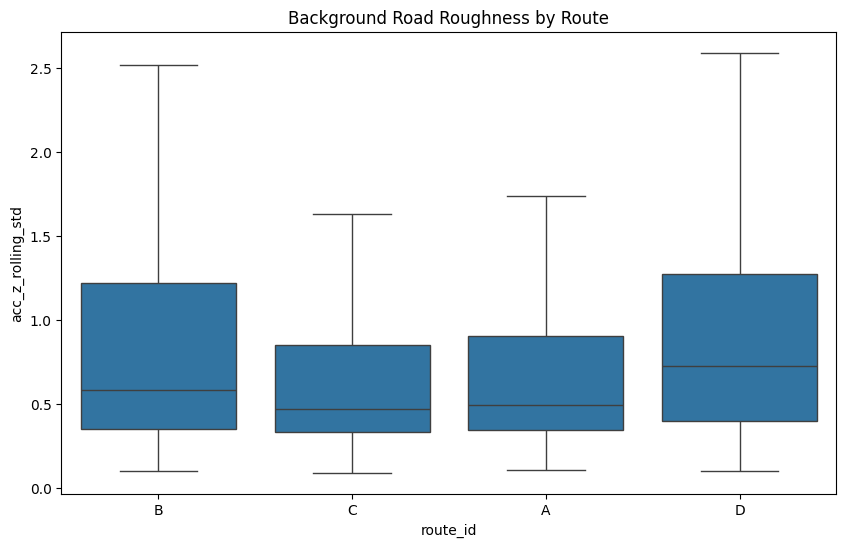

,acc_z_rolling_std
ride_id,
R07,0.539
R09,0.570
R01,0.656
R06,0.664
R02,0.701
R08,0.722
R03,0.754
R04,0.793
R11,0.878


In [102]:
smooth_only = df[df['label'] == 0]

plt.figure(figsize=(10, 6))
sns.boxplot(data=smooth_only.sample(min(40000, len(smooth_only)), random_state=42),
            x='route_id', y='acc_z_rolling_std', showfliers=False)
plt.title('Background Road Roughness by Route')
plt.show()

smooth_only.groupby('ride_id')['acc_z_rolling_std'].mean().round(3).sort_values()

**Insight:** background roughness differs by route. Test route D is the roughest (mean rolling std 0.893) vs 0.705, 0.829 and 0.676 for the training routes. This is a real distribution shift, so scores on route D will be lower than in-route scores.

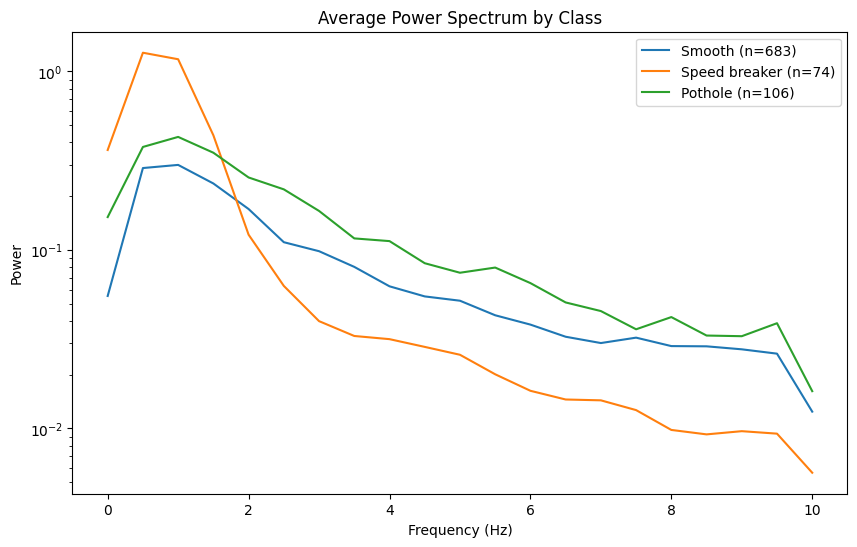

In [103]:
from scipy.signal import welch

rng = np.random.default_rng(42)
wins = {0: [], 1: [], 2: []}
for rid, g in df.groupby('ride_id'):
    z = g['acc_z_dyn'].to_numpy(); lab = g['label'].to_numpy(); st = g['event_start'].to_numpy()
    for s in np.where(st)[0]:
        if s + 40 <= len(z):
            wins[lab[s]].append(z[s:s + 40])
    for _ in range(60):
        s = rng.integers(0, len(z) - 40)
        if lab[s:s + 40].sum() == 0:
            wins[0].append(z[s:s + 40])

plt.figure(figsize=(10, 6))
for k, name in [(0, 'Smooth'), (1, 'Speed breaker'), (2, 'Pothole')]:
    f, P = welch(np.array(wins[k]), fs=20, nperseg=40, axis=1)
    plt.semilogy(f, P.mean(axis=0), label=f'{name} (n={len(wins[k])})')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Power')
plt.title('Average Power Spectrum by Class'); plt.legend()
plt.show()

**Insight:** speed breakers are dominated by low-frequency energy (about 87% of power below 2 Hz vs about 49% for smooth road). Potholes have a similar spectrum shape to smooth road but about 1.5 times more total power, so they are separated by amplitude more than by frequency. Both ideas are used as window features below.

In [104]:
import folium

m = folium.Map(location=[df['lat'].mean(), df['lon'].mean()], zoom_start=12)
colors = {'A': 'blue', 'B': 'green', 'C': 'purple', 'D': 'black'}
for rid, g in df.groupby('ride_id'):
    g = g.iloc[::20]
    folium.PolyLine(g[['lat', 'lon']].values.tolist(),
                    color=colors[g['route_id'].iloc[0]], weight=3, opacity=0.6).add_to(m)
for _, r in df[df['event_start']].iterrows():
    folium.CircleMarker([r['lat'], r['lon']], radius=4,
                        color='orange' if r['label'] == 1 else 'red',
                        fill=True, popup=event_names[r['label']]).add_to(m)
m

In [105]:
df.to_csv('road_sensor_clean.csv', index=False)

## Key EDA findings

1. **Severe imbalance:** 98.67% smooth, 0.88% speed breaker, 0.45% pothole rows. Use class weights and macro-F1.
2. **Size:** 74 speed breakers and 106 potholes across 12 rides on 4 routes at 20 Hz.
3. **Duration:** speed breakers last about 1.05 s and potholes about 0.38 s, so a 2-second window covers both.
4. **Shapes differ:** a speed breaker is a slow rise and fall, and a pothole is a sharp dip and rebound.
5. **A simple threshold fails:** only 51.5% of pothole rows exceed |acc_z| of 3, and 87.3% of big jolts are normal rough road.
6. **Speed matters for breakers:** about 12.3 km/h at breakers vs 28.5 km/h elsewhere. No such effect for potholes.
7. **Distribution shift:** test route D is rougher than the training routes (mean rolling std 0.893 vs 0.676 to 0.829).
8. **Data quality:** about 1.97% of GPS values were missing in short gaps and were interpolated per ride.

**Modeling plan:** build 2-second windows with a 1-second step, use gravity-removed features plus speed and band power, split **by route** (route D is the test set), use class weights, and compare models with macro-F1 and per-class recall.

In [106]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

fitted = {}
preds = {}

## Windowing and train/test split

Single sensor readings cannot show an event's shape, so the raw signals are cut into **2-second windows (40 readings) with a 1-second step**. Each window gets summary features (spread, extremes, shape, rotation, speed, and share of power in frequency bands). A window's label is the highest label inside it.

**Split by route, not at random.** Neighbouring windows from the same ride look almost identical, so a random split leaks information from train into test and inflates scores. Routes A, B and C are used for training and cross-validation, and **route D is held out as the final test**.

In [107]:
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import skew, kurtosis

WIN, STEP, FS = 40, 20, 20   # 2 s windows, 1 s step, 20 Hz

def win(a):
    return sliding_window_view(a, WIN)[::STEP]

rows = []
for rid, g in df.groupby('ride_id'):
    z, x, y = win(g['acc_z_dyn'].to_numpy()), win(g['acc_x'].to_numpy()), win(g['acc_y'].to_numpy())
    gx, gy, gz = win(g['gyro_x'].to_numpy()), win(g['gyro_y'].to_numpy()), win(g['gyro_z'].to_numpy())
    sp, lab = win(g['speed_kmh'].to_numpy()), win(g['label'].to_numpy())
    t0, la, lo = win(g['time_s'].to_numpy()), win(g['lat'].to_numpy()), win(g['lon'].to_numpy())

    power = np.abs(np.fft.rfft(z, axis=1))**2
    freqs = np.fft.rfftfreq(WIN, 1/FS)
    tot = power.sum(axis=1) + 1e-9

    feat = pd.DataFrame({
        'z_std': z.std(1), 'z_mean': z.mean(1), 'z_max': z.max(1), 'z_min': z.min(1),
        'z_range': z.max(1) - z.min(1), 'z_absmax': np.abs(z).max(1),
        'z_skew': skew(z, axis=1), 'z_kurt': kurtosis(z, axis=1),
        'x_std': x.std(1), 'y_mean': y.mean(1), 'y_std': y.std(1),
        'gx_std': gx.std(1), 'gy_std': gy.std(1), 'gz_std': gz.std(1),
        'gx_absmax': np.abs(gx).max(1),
        'speed_mean': sp.mean(1), 'speed_min': sp.min(1),
        'speed_range': sp.max(1) - sp.min(1),
        'pow_0_2hz': power[:, (freqs >= 0) & (freqs < 2)].sum(1) / tot,
        'pow_2_5hz': power[:, (freqs >= 2) & (freqs < 5)].sum(1) / tot,
        'pow_5_10hz': power[:, freqs >= 5].sum(1) / tot,
        'label': lab.max(1),
        'start_time': t0[:, 0], 'lat': la.mean(1), 'lon': lo.mean(1),
    })
    feat.insert(0, 'ride_id', rid)
    feat.insert(1, 'route_id', g['route_id'].iloc[0])
    rows.append(feat)

window_df = pd.concat(rows, ignore_index=True).dropna()
print(window_df.shape)
window_df['label'].value_counts(normalize=True).round(4)

(8872, 27)


,proportion
label,
0,0.9478
2,0.0276
1,0.0246


In [108]:
train = window_df[window_df['route_id'] != 'D']
test  = window_df[window_df['route_id'] == 'D']

non_features = ['ride_id', 'route_id', 'label', 'start_time', 'lat', 'lon']
feat_cols = [c for c in window_df.columns if c not in non_features]

X_train, y_train = train[feat_cols], train['label']
X_test,  y_test  = test[feat_cols],  test['label']

print("Train:", X_train.shape, "| Test (route D):", X_test.shape)
print("Test class counts:", y_test.value_counts().sort_index().to_dict())

Train: (7595, 21) | Test (route D): (1277, 21)
Test class counts: {0: 1209, 1: 29, 2: 39}


In [109]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=3000)
)
log_reg.fit(X_train, y_train)

fitted['Logistic Regression'] = log_reg
preds['Logistic Regression'] = log_reg.predict(X_test)
print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


## Models

Three models are compared: **Logistic Regression** (simple baseline), **Random Forest** and **XGBoost**. All handle class imbalance with class weights (XGBoost uses sample weights).

In [110]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

fitted['Random Forest'] = rf
preds['Random Forest'] = rf.predict(X_test)
print("Random Forest trained")

Random Forest trained


In [111]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    eval_metric='mlogloss'
)

xgb.fit(X_train, y_train, sample_weight=compute_sample_weight('balanced', y_train))

fitted['XGBoost'] = xgb
preds['XGBoost'] = xgb.predict(X_test)
print("XGBoost trained")

XGBoost trained


## Evaluation

Because about 95% of windows are smooth road, an "always smooth" dummy model scores about 95% accuracy while finding nothing. Models are judged by **macro-F1**, **balanced accuracy**, **per-class recall**, precision-recall curves, and **leave-one-route-out cross-validation**, with bootstrap error bars because the test set is small.

In [112]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix, matthews_corrcoef)
from sklearn.dummy import DummyClassifier

class_names = ['Smooth', 'Speed breaker', 'Pothole']
model_names = ['Logistic Regression', 'Random Forest', 'XGBoost']

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
all_models = {'Dummy (always smooth)': dummy, **fitted}
all_preds = {name: m.predict(X_test) for name, m in all_models.items()}

rows = []
for name, p in all_preds.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, p),
        'Balanced accuracy': balanced_accuracy_score(y_test, p),
        'Macro precision': precision_score(y_test, p, average='macro', zero_division=0),
        'Macro recall': recall_score(y_test, p, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, p, average='macro', zero_division=0),
        'MCC': matthews_corrcoef(y_test, p),
    })
metrics = pd.DataFrame(rows).set_index('Model').round(3)
metrics

,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,MCC
Model,,,,,,
Dummy (always smooth),0.947,0.333,0.316,0.333,0.324,0.000
Logistic Regression,0.930,0.925,0.620,0.925,0.712,0.613
Random Forest,0.990,0.894,0.972,0.894,0.930,0.896
XGBoost,0.990,0.933,0.943,0.933,0.938,0.900


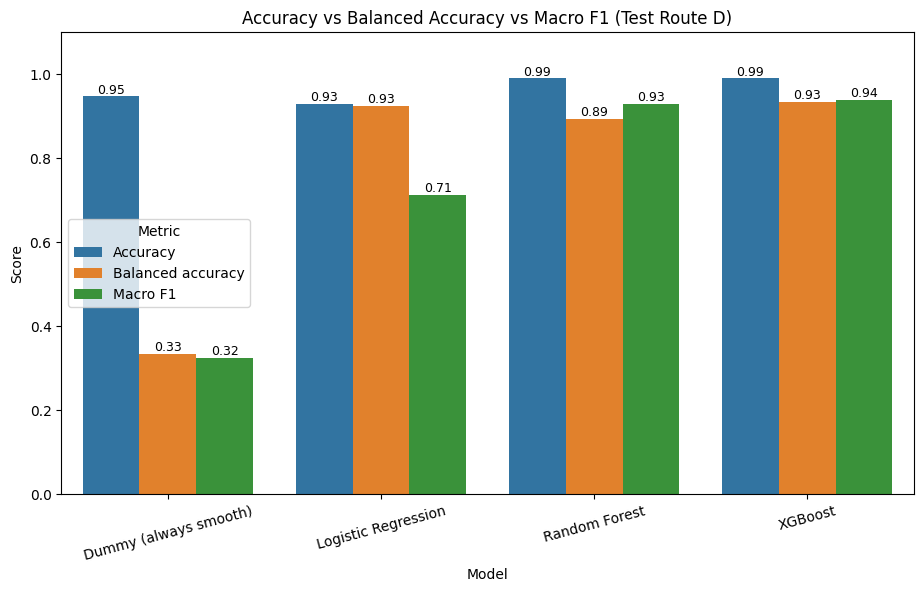

In [113]:
plot_df = (metrics[['Accuracy', 'Balanced accuracy', 'Macro F1']]
           .reset_index().melt(id_vars='Model', var_name='Metric', value_name='Score'))

plt.figure(figsize=(11, 6))
ax = sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=9)
plt.ylim(0, 1.1)
plt.title('Accuracy vs Balanced Accuracy vs Macro F1 (Test Route D)')
plt.xticks(rotation=15)
plt.show()

In [114]:
for name in model_names:
    print('=' * 60)
    print(name)
    print('=' * 60)
    print(classification_report(y_test, all_preds[name], target_names=class_names,
                                digits=3, zero_division=0))

Logistic Regression
               precision    recall  f1-score   support

       Smooth      0.996     0.931     0.962      1209
Speed breaker      0.456     0.897     0.605        29
      Pothole      0.407     0.949     0.569        39

     accuracy                          0.930      1277
    macro avg      0.620     0.925     0.712      1277
 weighted avg      0.966     0.930     0.942      1277

Random Forest
               precision    recall  f1-score   support

       Smooth      0.991     0.998     0.995      1209
Speed breaker      0.926     0.862     0.893        29
      Pothole      1.000     0.821     0.901        39

     accuracy                          0.990      1277
    macro avg      0.972     0.894     0.930      1277
 weighted avg      0.990     0.990     0.989      1277

XGBoost
               precision    recall  f1-score   support

       Smooth      0.994     0.995     0.995      1209
Speed breaker      0.964     0.931     0.947        29
      Pothole   

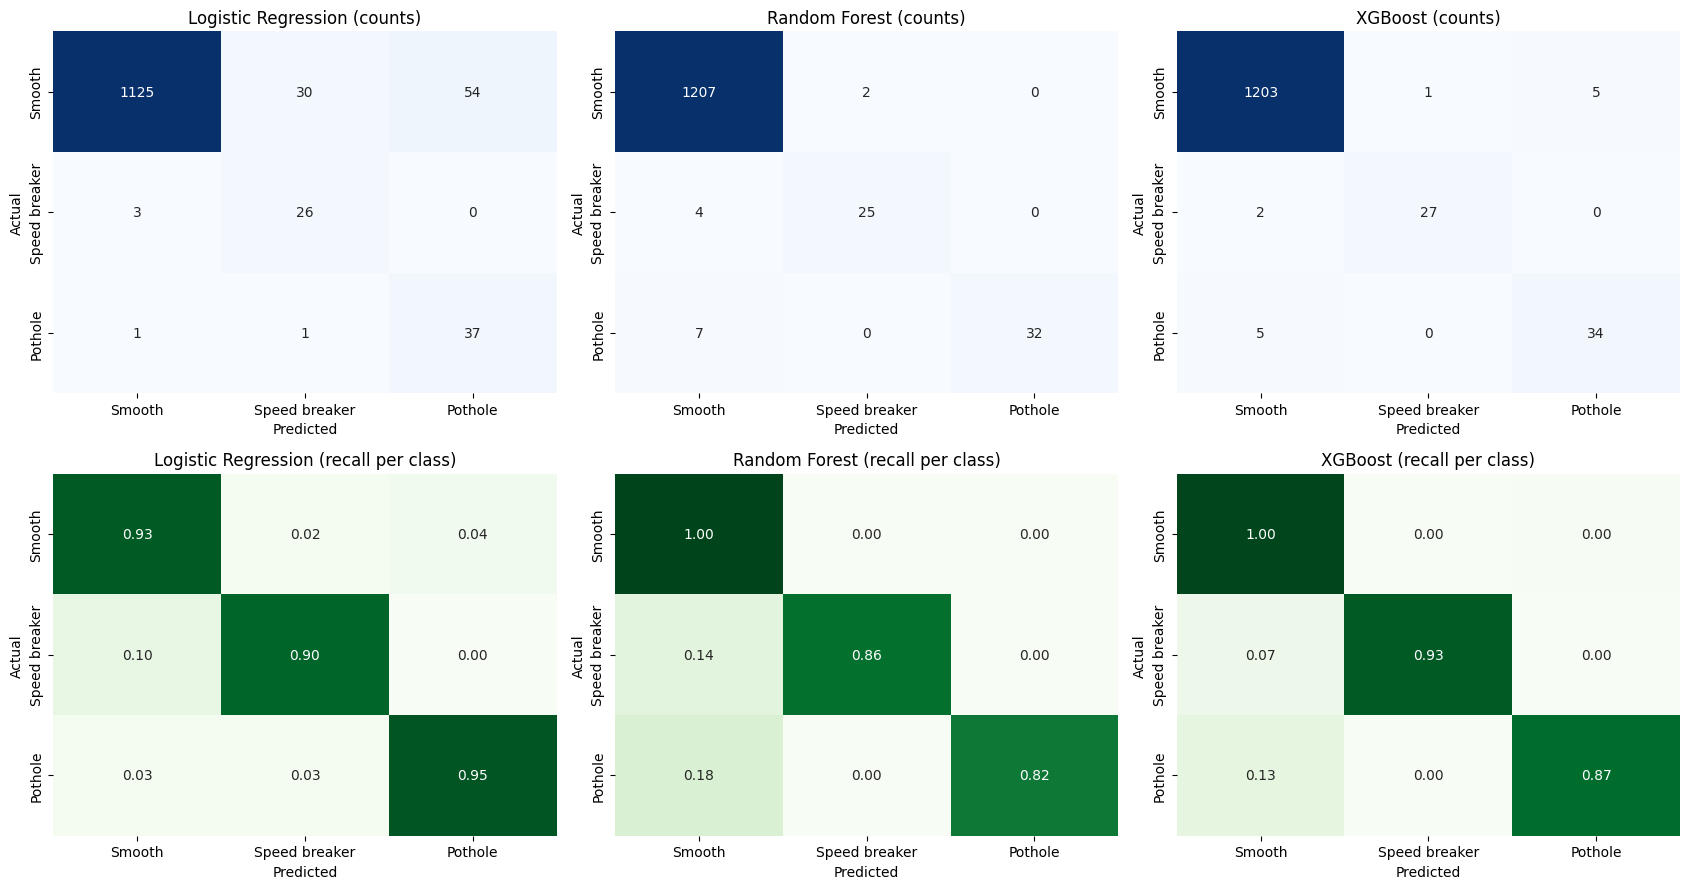

In [115]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, name in enumerate(model_names):
    cm = confusion_matrix(y_test, all_preds[name])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, i],
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    axes[0, i].set_title(f'{name} (counts)')

    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens', ax=axes[1, i],
                xticklabels=class_names, yticklabels=class_names, cbar=False, vmin=0, vmax=1)
    axes[1, i].set_title(f'{name} (recall per class)')

    for r in range(2):
        axes[r, i].set_xlabel('Predicted')
        axes[r, i].set_ylabel('Actual')
plt.tight_layout()
plt.show()

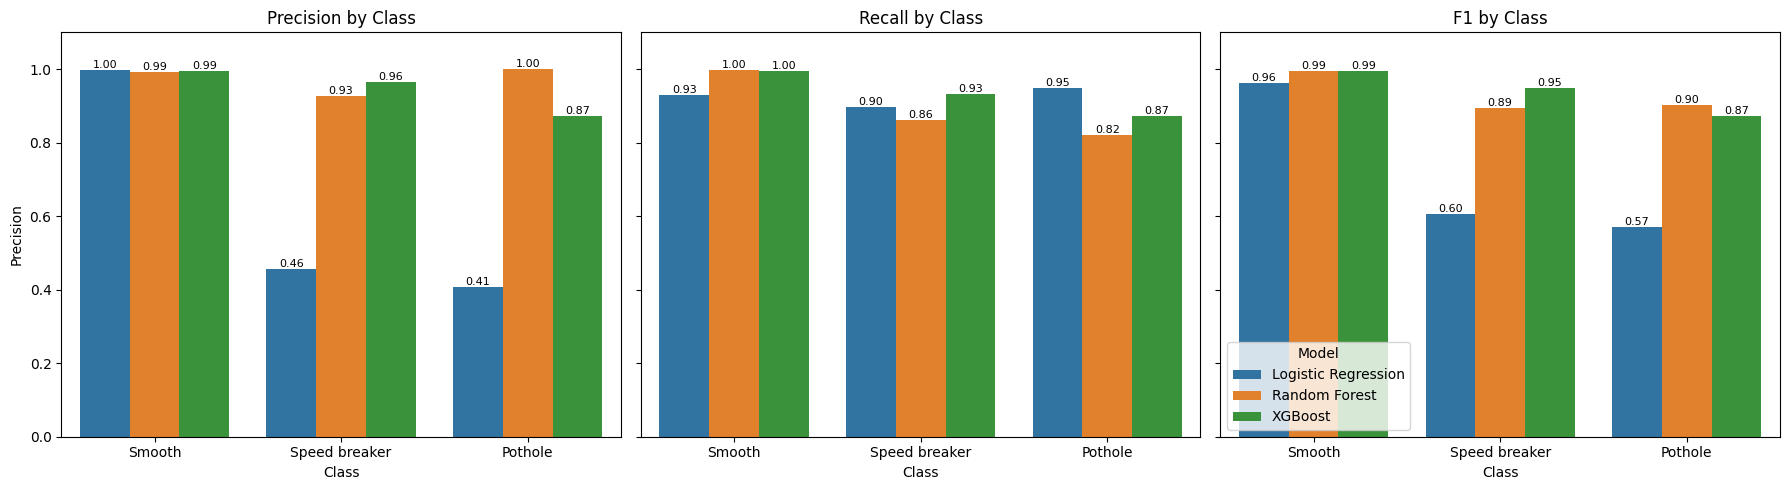

Model,Logistic Regression,Random Forest,XGBoost
Class,,,
Pothole,0.949,0.821,0.872
Smooth,0.931,0.998,0.995
Speed breaker,0.897,0.862,0.931


In [116]:
from sklearn.metrics import precision_recall_fscore_support

rows = []
for name in model_names:
    pr, rc, f1, _ = precision_recall_fscore_support(
        y_test, all_preds[name], labels=[0, 1, 2], zero_division=0)
    for k, cls in enumerate(class_names):
        rows.append({'Model': name, 'Class': cls,
                     'Precision': pr[k], 'Recall': rc[k], 'F1': f1[k]})
per_class = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, metric in zip(axes, ['Precision', 'Recall', 'F1']):
    sns.barplot(data=per_class, x='Class', y=metric, hue='Model', ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.2f', fontsize=8)
    ax.set_title(f'{metric} by Class')
    ax.set_ylim(0, 1.1)
    if ax is not axes[-1]:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()

per_class.pivot(index='Class', columns='Model', values='Recall').round(3)

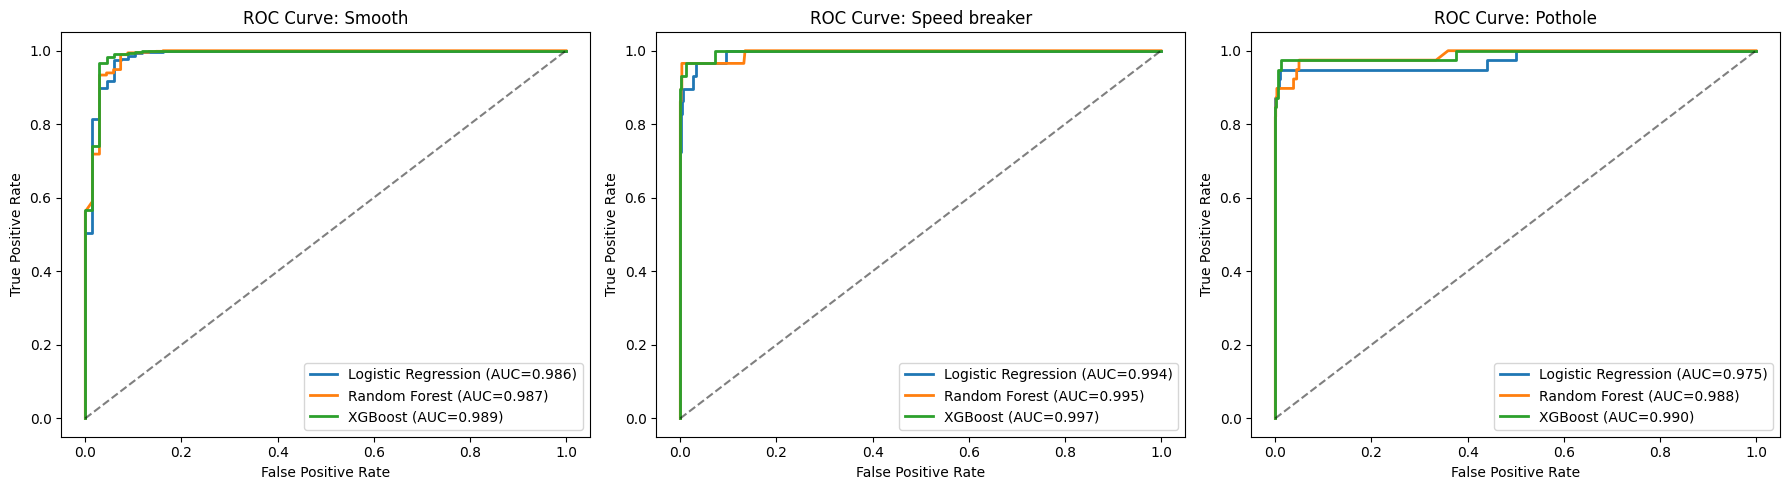

,Macro ROC-AUC
Logistic Regression,0.985
Random Forest,0.990
XGBoost,0.992


In [117]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(y_test, classes=[0, 1, 2])
proba = {name: fitted[name].predict_proba(X_test) for name in model_names}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for k, cls in enumerate(class_names):
    for name in model_names:
        fpr, tpr, _ = roc_curve(y_bin[:, k], proba[name][:, k])
        axes[k].plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc(fpr, tpr):.3f})')
    axes[k].plot([0, 1], [0, 1], 'k--', alpha=0.5)
    axes[k].set_title(f'ROC Curve: {cls}')
    axes[k].set_xlabel('False Positive Rate')
    axes[k].set_ylabel('True Positive Rate')
    axes[k].legend(loc='lower right')
plt.tight_layout()
plt.show()

auc_table = pd.DataFrame({
    name: {'Macro ROC-AUC': roc_auc_score(y_test, proba[name], multi_class='ovr', average='macro')}
    for name in model_names}).T.round(3)
auc_table

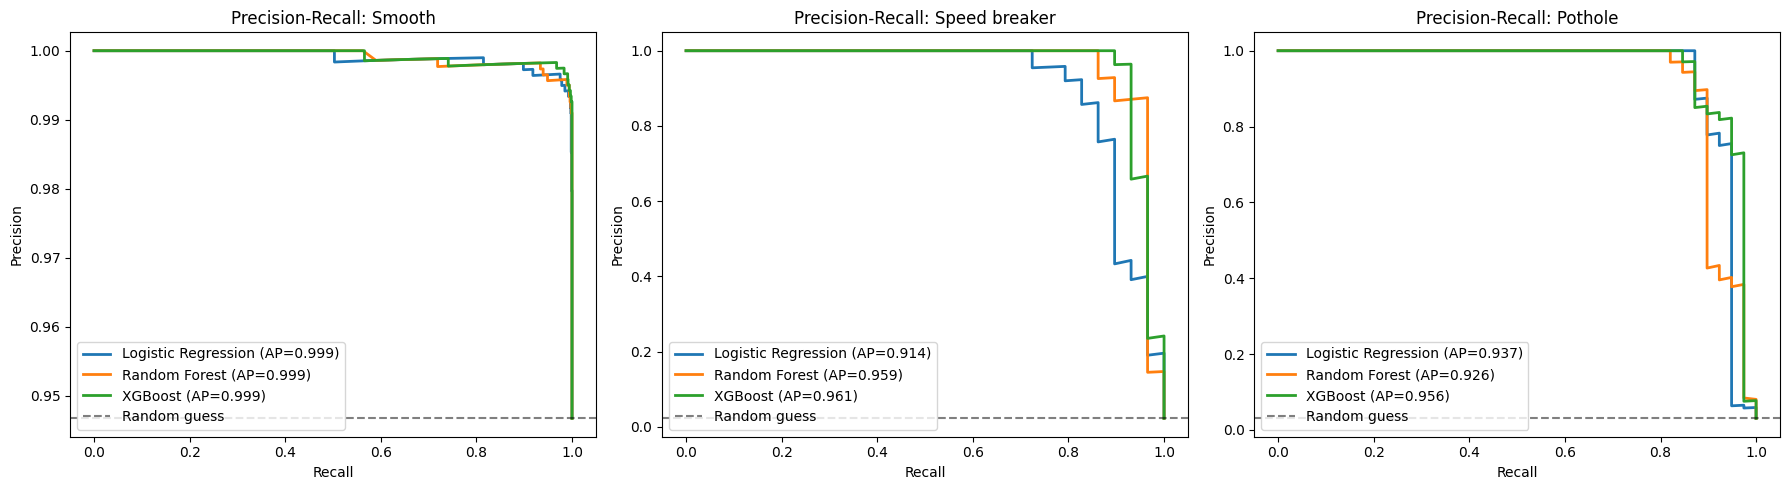

Model,Logistic Regression,Random Forest,XGBoost
Class,,,
Pothole,0.937,0.926,0.956
Smooth,0.999,0.999,0.999
Speed breaker,0.914,0.959,0.961


In [118]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ap_rows = []
for k, cls in enumerate(class_names):
    baseline = y_bin[:, k].mean()
    for name in model_names:
        prec, rec, _ = precision_recall_curve(y_bin[:, k], proba[name][:, k])
        ap = average_precision_score(y_bin[:, k], proba[name][:, k])
        axes[k].plot(rec, prec, linewidth=2, label=f'{name} (AP={ap:.3f})')
        ap_rows.append({'Class': cls, 'Model': name, 'Average Precision': ap})
    axes[k].axhline(baseline, color='k', linestyle='--', alpha=0.5, label='Random guess')
    axes[k].set_title(f'Precision-Recall: {cls}')
    axes[k].set_xlabel('Recall')
    axes[k].set_ylabel('Precision')
    axes[k].legend(loc='lower left')
plt.tight_layout()
plt.show()

pd.DataFrame(ap_rows).pivot(index='Class', columns='Model', values='Average Precision').round(3)

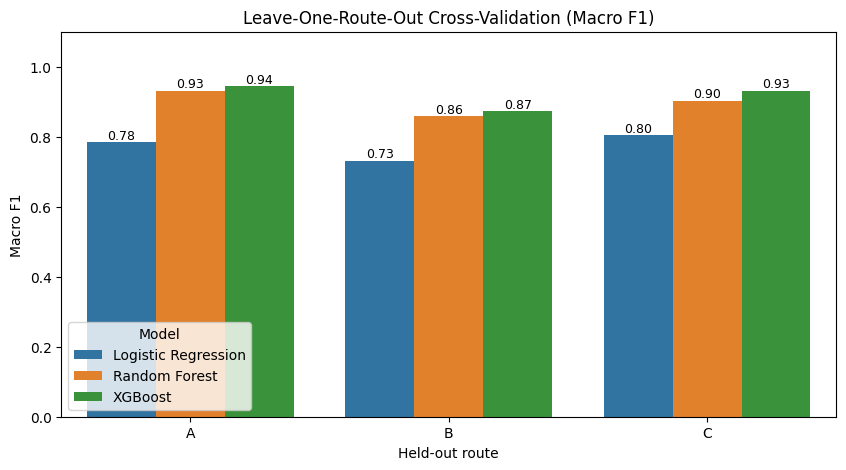

,mean,std
Model,,
Logistic Regression,0.773,0.037
Random Forest,0.898,0.036
XGBoost,0.917,0.038


In [119]:
from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut

def fit_any(name, model, X, y):
    if name == 'XGBoost':
        model.fit(X, y, sample_weight=compute_sample_weight('balanced', y))
    else:
        model.fit(X, y)
    return model

groups = train['route_id']
cv_rows = []
for name in model_names:
    for tr, va in LeaveOneGroupOut().split(X_train, y_train, groups):
        m = fit_any(name, clone(fitted[name]), X_train.iloc[tr], y_train.iloc[tr])
        p = m.predict(X_train.iloc[va])
        cv_rows.append({'Model': name,
                        'Held-out route': groups.iloc[va].iloc[0],
                        'Macro F1': f1_score(y_train.iloc[va], p, average='macro')})
cv_df = pd.DataFrame(cv_rows)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=cv_df, x='Held-out route', y='Macro F1', hue='Model')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=9)
plt.ylim(0, 1.1)
plt.title('Leave-One-Route-Out Cross-Validation (Macro F1)')
plt.show()

cv_df.groupby('Model')['Macro F1'].agg(['mean', 'std']).round(3)

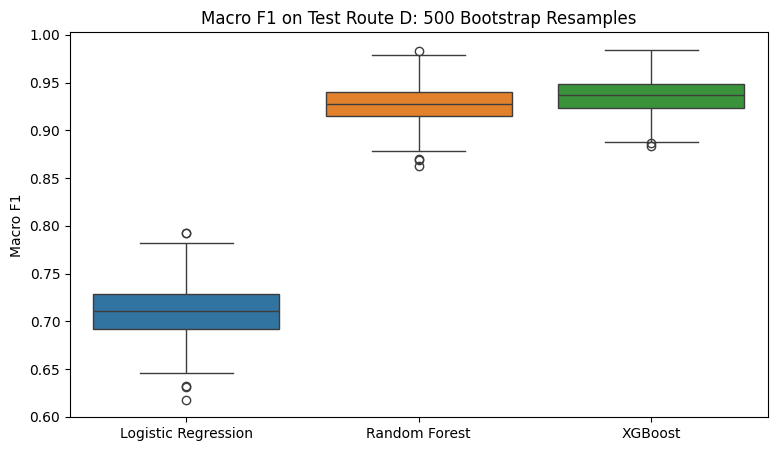

,2.5%,Median,97.5%
Logistic Regression,0.659,0.711,0.765
Random Forest,0.889,0.927,0.962
XGBoost,0.902,0.936,0.970


In [120]:
rng = np.random.default_rng(42)
y_arr = y_test.to_numpy()
n = len(y_arr)

boot = {name: [] for name in model_names}
for _ in range(500):
    idx = rng.integers(0, n, n)
    for name in model_names:
        boot[name].append(f1_score(y_arr[idx], all_preds[name][idx], average='macro', zero_division=0))

boot_df = pd.DataFrame(boot)

plt.figure(figsize=(9, 5))
sns.boxplot(data=boot_df)
plt.title('Macro F1 on Test Route D: 500 Bootstrap Resamples')
plt.ylabel('Macro F1')
plt.show()

ci = boot_df.quantile([0.025, 0.5, 0.975]).T
ci.columns = ['2.5%', 'Median', '97.5%']
ci.round(3)

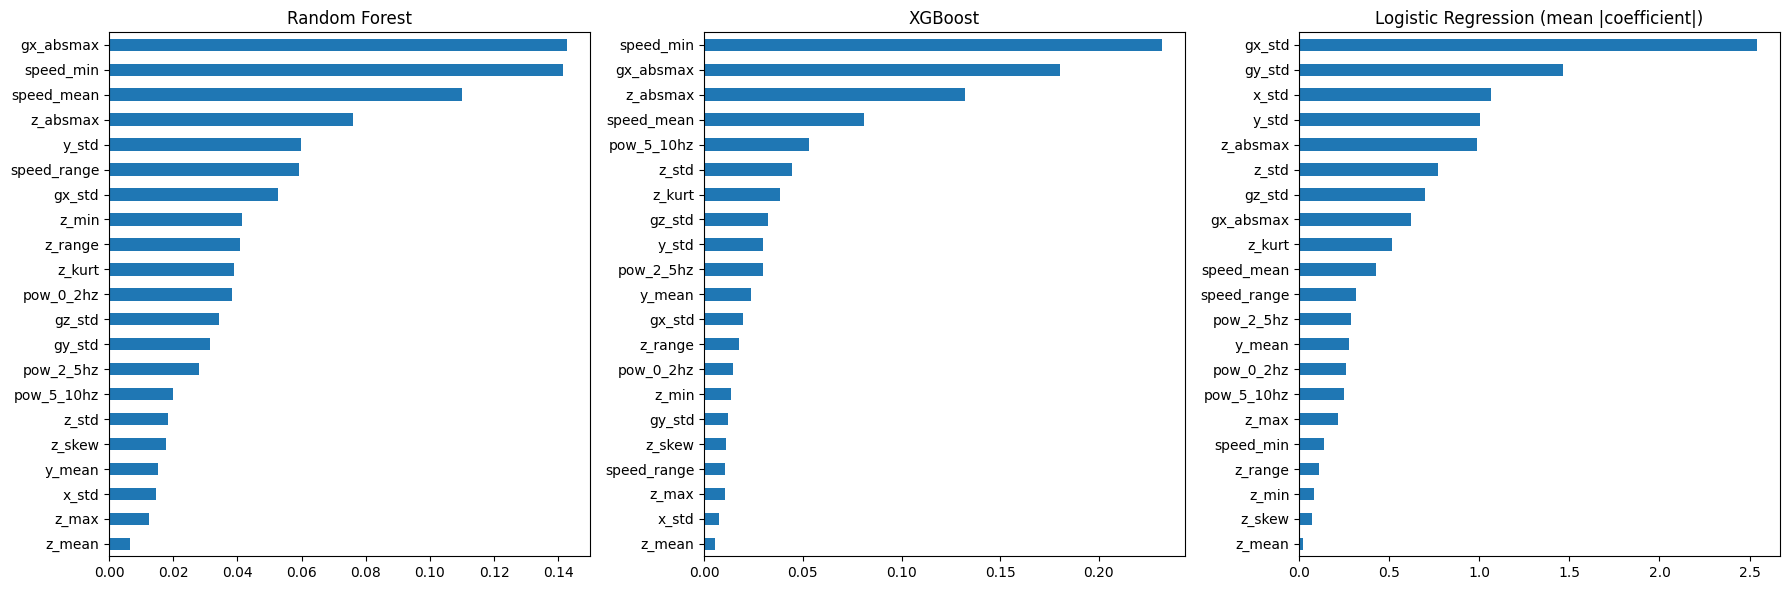

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

pd.Series(fitted['Random Forest'].feature_importances_, index=feat_cols).sort_values().plot(
    kind='barh', ax=axes[0], title='Random Forest')
pd.Series(fitted['XGBoost'].feature_importances_, index=feat_cols).sort_values().plot(
    kind='barh', ax=axes[1], title='XGBoost')

lr_coef = fitted['Logistic Regression'].named_steps['logisticregression'].coef_
pd.Series(np.abs(lr_coef).mean(axis=0), index=feat_cols).sort_values().plot(
    kind='barh', ax=axes[2], title='Logistic Regression (mean |coefficient|)')

plt.tight_layout()
plt.show()

In [122]:
final = metrics.drop('Dummy (always smooth)')[['Accuracy', 'Macro F1', 'MCC']].copy()
final['CV Macro F1'] = cv_df.groupby('Model')['Macro F1'].mean()
final['Macro ROC-AUC'] = auc_table['Macro ROC-AUC']
final['Pothole recall'] = per_class[per_class['Class'] == 'Pothole'].set_index('Model')['Recall']
final['Speed breaker recall'] = per_class[per_class['Class'] == 'Speed breaker'].set_index('Model')['Recall']
final = final.round(3).sort_values('Macro F1', ascending=False)

print("Best model by test Macro F1:", final.index[0])
final.to_csv('model_comparison.csv')
final

Best model by test Macro F1: XGBoost


,Accuracy,Macro F1,MCC,CV Macro F1,Macro ROC-AUC,Pothole recall,Speed breaker recall
Model,,,,,,,
XGBoost,0.99,0.938,0.900,0.917,0.992,0.872,0.931
Random Forest,0.99,0.930,0.896,0.898,0.990,0.821,0.862
Logistic Regression,0.93,0.712,0.613,0.773,0.985,0.949,0.897


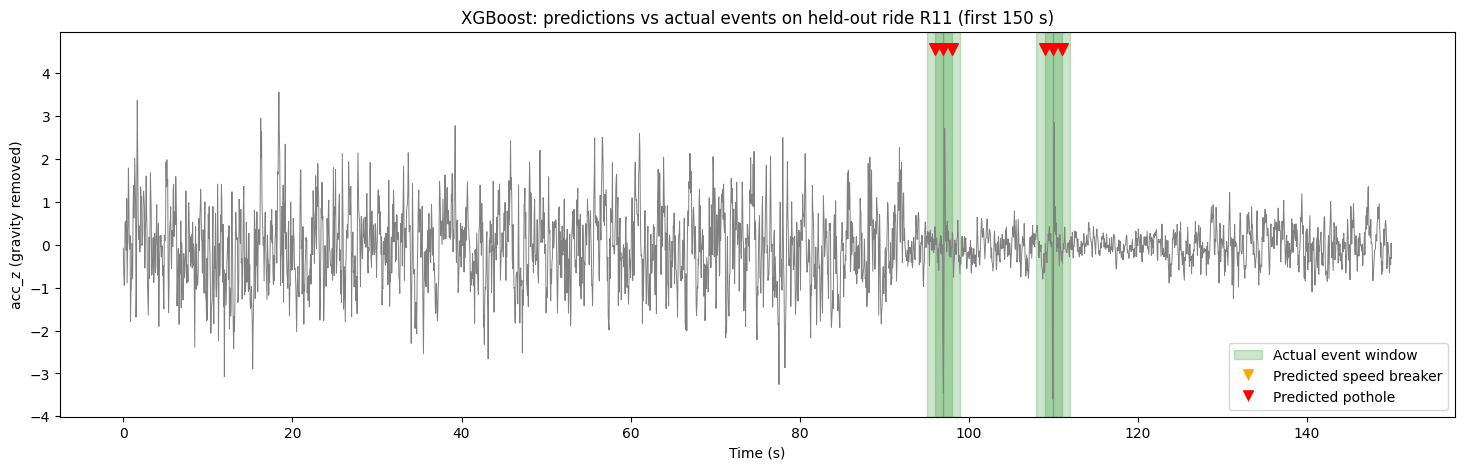

In [123]:
best_name = final.index[0]
best_model = fitted[best_name]
test_out = test.copy()
test_out['pred'] = best_model.predict(X_test)

ride_id = 'R11'   # a ride from the held-out test route D
r = df[(df['ride_id'] == ride_id) & (df['time_s'] <= 150)]
sub = test_out[(test_out['ride_id'] == ride_id) & (test_out['start_time'] <= 150)]

fig, ax = plt.subplots(figsize=(18, 5))
ax.plot(r['time_s'], r['acc_z_dyn'], color='gray', linewidth=0.7)
for _, w in sub[sub['label'] > 0].iterrows():
    ax.axvspan(w['start_time'], w['start_time'] + 2, color='green', alpha=0.2)
top = r['acc_z_dyn'].max() + 1
for _, w in sub[sub['pred'] == 1].iterrows():
    ax.scatter(w['start_time'] + 1, top, marker='v', color='orange', s=70)
for _, w in sub[sub['pred'] == 2].iterrows():
    ax.scatter(w['start_time'] + 1, top, marker='v', color='red', s=70)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[
    Patch(color='green', alpha=0.2, label='Actual event window'),
    Line2D([0], [0], marker='v', color='w', markerfacecolor='orange', markersize=10, label='Predicted speed breaker'),
    Line2D([0], [0], marker='v', color='w', markerfacecolor='red', markersize=10, label='Predicted pothole')],
    loc='lower right')
ax.set_title(f'{best_name}: predictions vs actual events on held-out ride {ride_id} (first 150 s)')
ax.set_xlabel('Time (s)'); ax.set_ylabel('acc_z (gravity removed)')
plt.show()

In [124]:
import folium

m = folium.Map(location=[test_out['lat'].mean(), test_out['lon'].mean()], zoom_start=14)
for rid, g in test_out.groupby('ride_id'):
    folium.PolyLine(g[['lat', 'lon']].values.tolist(), color='gray', weight=3, opacity=0.6).add_to(m)
for _, w in test_out[test_out['pred'] > 0].iterrows():
    folium.CircleMarker([w['lat'], w['lon']], radius=5,
                        color='orange' if w['pred'] == 1 else 'red', fill=True,
                        popup=f"Predicted: {class_names[int(w['pred'])]}").add_to(m)
m

In [126]:
import joblib

best_name = final.index[0]
best_model = fitted[best_name]

# Fix: Use 'feat_cols' which contains the list of feature column names
features_to_save = feat_cols

FS = 20
WIN = 40
STEP = 20

joblib.dump({
    'model': best_model,
    'model_name': best_name,
    'feature_columns': features_to_save,
    'class_names': class_names,
    'window_size': WIN,
    'step': STEP,
    'sampling_hz': FS
}, 'road_quality_model.joblib')

print(f"Saved {best_name} to road_quality_model.joblib")

Saved XGBoost to road_quality_model.joblib


In [127]:
import json, joblib, numpy as np
non_features = ['ride_id','route_id','label','start_time','lat','lon']
feat_cols = [c for c in window_df.columns if c not in non_features]
best_name = final.index[0]; best_model = fitted[best_name]

joblib.dump({'model': best_model, 'model_name': best_name, 'feature_columns': feat_cols,
             'class_names': class_names, 'window_size': 40, 'step': 20, 'sampling_hz': 20},
            'road_quality_model.joblib')

tw = window_df[window_df.route_id != 'D']
ref = {'features': {c: {'mean': float(tw[c].mean()), 'std': float(tw[c].std()),
                        'p05': float(tw[c].quantile(.05)), 'p95': float(tw[c].quantile(.95))} for c in feat_cols},
       'smooth_z_std': {k: float(v) for k, v in tw[tw.label == 0]['z_std'].describe().items()},
       'train_routes': ['A','B','C'], 'test_route': 'D'}
json.dump(ref, open('reference_stats.json', 'w'), indent=2)

raw_cols = ['ride_id','route_id','time_s','lat','lon','speed_kmh','acc_x','acc_y','acc_z','gyro_x','gyro_y','gyro_z','label']
for rid in ['R01','R05','R10','R11','R12']:
    df[df.ride_id == rid][raw_cols].to_csv(f'ride_{rid}.csv', index=False)
window_df.to_csv('training_windows.csv', index=False)
cv_df.to_csv('cv_results.csv', index=False); per_class.to_csv('per_class_metrics.csv', index=False)
final.to_csv('model_comparison.csv')

## Conclusions

| Model | Test macro-F1 | CV macro-F1 | Pothole recall | Speed breaker recall |
|---|---|---|---|---|
| XGBoost | 0.938 | 0.917 | 0.872 | 0.931 |
| Random Forest | 0.930 | 0.898 | 0.821 | 0.862 |
| Logistic Regression | 0.712 | 0.773 | 0.949 | 0.897 |
| Dummy (always smooth) | 0.324 | not run | 0.000 | 0.000 |

- **XGBoost and Random Forest perform about the same.** Their bootstrap 95% intervals for macro-F1 (about 0.90 to 0.97 and 0.89 to 0.96) overlap almost completely.
- **Logistic Regression is clearly weaker.** It catches the most potholes but raises many false alarms. Its high ROC-AUC (0.985) shows the decision threshold is the issue.
- **Accuracy is misleading.** The dummy model reaches about 95% accuracy while detecting nothing.

## Limitations
- The data is **simulated**, so scores describe simulated patterns, not real roads.
- The test set is small (about 29 speed breakers and 39 potholes on one route), so scores have wide error bars.
- Overlapping windows produce several flagged windows per event.
- One phone position is assumed, and no threshold or hyper-parameter tuning was done.

## Next steps
1. Tune XGBoost with route-grouped cross-validation.
2. Move the decision threshold to raise pothole recall.
3. Validate on a few real recorded rides.
4. Wrap the saved model in a Streamlit app that returns a road-quality map.
